# Introduction to Machine Learning -- MC886A/MO444A
# Assignment 3 - Neural Networks, Inductive Bias and Distribution Shift

**Professor:** Marcelo da Silva Reis

**PED:** Heigon Soldera

In [1]:
# Enter your name and RA number below.

print("Lucas Treviso Bandeira", "|", "322979")
print("Mariana Dourado Ximenes de Sena Santos", "|", "300643")

Lucas Treviso Bandeira | 322979
Mariana Dourado Ximenes de Sena Santos | 300643


---

## Objective

In Assignment 2 you saw that the model selected by cross-validation on the training distribution is not
necessarily the most robust one when the test distribution changes. There, the assumption we varied was the
**penalty** of a linear model. In this assignment we vary the **architecture**.

A multilayer perceptron (MLP) and a convolutional neural network (CNN) can both fit a training set almost
perfectly, but they do it under different assumptions about the input, their **inductive biases**:
- an MLP gives every pixel position its own weight and knows nothing about which pixels are neighbors;
- a CNN detects local patterns with small filters that are shared across all positions, and combines them
  hierarchically.

When several hypotheses explain the training data equally well, these assumptions decide which one the network
learns, and the difference only shows up when the test distribution changes. For example, a classifier of
histopathology images can recognize a type of tissue from the shape and the arrangement of its cells, which are the
same in every hospital, or from the exact colors produced by the staining protocol of the hospital where the
training images were acquired. Both solutions fit the training set, but only one of them survives a new hospital.

The goal of this assignment is to test, with controlled experiments, which structural assumptions and which training
choices help a neural network generalize to a clinical center it has never seen.

### Guidelines

> Please read these guidelines carefully.

1. Answers can be written in English or Portuguese.

2. Use data visualization as a primary tool for understanding. Inspect the training data, the transformed inputs, and
   model behavior. When an assumption is uncertain, verify it empirically through plots.

3. The provided code serves as a reference. Modifications are allowed, including changes to functions and the
   introduction of new components. Code clarity and organization are required. The hands-on of Lecture 18 (Deep
   Learning with PyTorch) contains reference implementations of the training loop, of an MLP, of a CNN and of data
   augmentation.

4. We recommend running this notebook on a GPU, for example on Google Colab (GPU runtime) or on a local GPU.

5. The use of generative AI tools (e.g., ChatGPT, GitHub Copilot, DeepSeek, LLaMA) is permitted strictly for
   **implementation support**. Their use for interpreting, analyzing, or discussing experimental results is
   discouraged. Submissions must include:
   - A declaration of which models were used.
   - The prompts that generated any incorporated code.

6. Do not hesitate to reach out to the PED/PAD via Discord.

### Experiment structure

Each experiment must follow the structure below:

1. **Question**: the empirical question guiding the exploration.
2. **Hypothesis**: a falsifiable answer to the question that makes a concrete, measurable prediction.
3. **Design**: justify why the proposed experiment can test the hypothesis. Focus on the reasoning, not on how the
   code works.
4. **Results**: run the experiment and report the metrics.
5. **Discussion**: interpret the results in terms of the hypothesis. Explicitly state whether the results support or
   contradict it, and why.

A hypothesis must be **falsifiable**: the proposed experiment must be capable of providing evidence *against* it.
Statements such as "the model is complex enough" or "the features are informative" do not qualify.

A negative result is not a failure: a well-reasoned experiment that contradicts the hypothesis is graded as highly as
one that confirms it, provided the interpretation is honest and coherent.

For Experiment 1, the question and hypothesis are given. Your task is to complete the missing code, write the design
justification, and discuss the results.
For Experiments 2-4, only the question is given. You must state the hypothesis and discuss the results; in
Experiments 2 and 3 you also justify the design, and in Experiment 4 you choose and evaluate the final model.

### Evaluation protocol

Throughout this assignment, **ID** (*in-distribution*) refers to patches from the same clinical center as the training
set, and **OOD** (*out-of-distribution*) to patches from a different center, which the model never sees during
training.

- **Model selection** (number of epochs, hyperparameters, early stopping, choice of the final model) uses only the
  **ID validation** split.
- The **OOD validation** split is used to *measure* the generalization gap in Experiments 1-4, never to choose
  hyperparameters or models.
- The **OOD test** split is used **only once**, at the end of Experiment 4. Do not look at its images or metrics
  before that.

In [2]:
import copy
import os
import random
import time
import urllib.request

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
from IPython.display import display

# ── Reproducibility ────────────────────────────────────────────────────────────
# Do not change this seed. Re-run the notebook from scratch before submitting.
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
torch.backends.cudnn.deterministic = True   # reproducible results on the GPU
torch.backends.cudnn.benchmark = False

DEVICE: str = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

Device: cuda


---

## Dataset — PathMNIST

Histopathology is the study of thin sections of tissue under a microscope, often to detect disease. The most common
technique stains the section with hematoxylin and eosin (H&E): hematoxylin colors the cell nuclei purple-blue, and
eosin colors the cytoplasm and the extracellular matrix pink, so the pathologist can tell the structures apart.

We use **PathMNIST**, from the [MedMNIST v2](https://medmnist.com/) benchmark, in its 64×64 version. Each sample is a
64×64 RGB patch of an H&E-stained section of colorectal tissue, labeled with one of **9 tissue classes**:

| Label | Tissue |
|---|---|
| 0 | adipose |
| 1 | background |
| 2 | debris |
| 3 | lymphocytes |
| 4 | mucus |
| 5 | smooth muscle |
| 6 | normal colon mucosa |
| 7 | cancer-associated stroma |
| 8 | colorectal adenocarcinoma epithelium |

The patches come from two datasets of the same study (Kather et al., 2019):
- the training and validation patches come from **NCT-CRC-HE-100K**;
- the test patches come from **CRC-VAL-HE-7K**, acquired at a **different clinical center**, with other patients.

Each center has its own staining protocol, scanner and population of patients, so the patches of the new center
differ from the training ones in ways that have nothing to do with the tissue class.

We use the following splits:

| Split | Source | Patches | Role in this assignment |
|---|---|---|---|
| `train` | NCT-CRC-HE-100K | 89,996 | Training |
| `id_val` | NCT-CRC-HE-100K | 10,004 | **ID validation**: early stopping and model selection |
| `ood_val` | CRC-VAL-HE-7K, first half | 3,590 | **OOD validation**: measures the generalization gap |
| `ood_test` | CRC-VAL-HE-7K, second half | 3,590 | **OOD test**: used only once, at the end of Experiment 4 |

The `id_val` patches were drawn at random from the same dataset as the training patches. The official test set of
PathMNIST is split in two halves, stratified by class, with the seed of this notebook. The two halves may contain
patches of the same patients, so they are not fully independent: `ood_test` protects the final result against
choices made *because* a model did well on `ood_val`, but not against everything the two halves have in common.

**Metrics.** We report the accuracy and the **balanced accuracy**, the mean of the recalls of the 9 classes
(`sklearn.metrics.balanced_accuracy_score`). Unlike the accuracy, the balanced accuracy does not change when only
the proportions of the classes change, which will matter in Experiment 4. The **ID–OOD gap**, the balanced accuracy
on `id_val` minus the balanced accuracy on `ood_val`, is the main measure of generalization to the new center.

The next cell downloads the 64×64 version of PathMNIST (about 1 GB, only once) from the
[MedMNIST repository on Zenodo](https://zenodo.org/records/10519652). Alternatively, you can download the data of this
assignment from our Google Classroom page: place the file `pathmnist_64.npz` in a folder named `data`, inside the
working directory of the notebook (on Colab, `/content/data`), and the cell will not download it again. You can also
install the `medmnist` package and use `medmnist.PathMNIST(split=..., size=64, download=True)`.

In [3]:
DATA_DIR = "data"
DATA_PATH = os.path.join(DATA_DIR, "pathmnist_64.npz")
DATA_URL = "https://zenodo.org/records/10519652/files/pathmnist_64.npz"

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_PATH):                    # download only once
    print("Downloading PathMNIST 64x64 (about 1 GB)...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

CLASSES = ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle",
           "normal colon mucosa", "cancer-associated stroma", "colorectal adenocarcinoma epithelium"]

with np.load(DATA_PATH) as f:
    # Images stay as uint8 (N, 3, 64, 64) to save memory; they are converted to float one batch at a time.
    X_train = torch.from_numpy(f["train_images"]).permute(0, 3, 1, 2).contiguous()
    y_train = torch.from_numpy(f["train_labels"]).long().squeeze(1)
    X_id_val = torch.from_numpy(f["val_images"]).permute(0, 3, 1, 2).contiguous()
    y_id_val = torch.from_numpy(f["val_labels"]).long().squeeze(1)
    X_external = torch.from_numpy(f["test_images"]).permute(0, 3, 1, 2).contiguous()
    y_external = torch.from_numpy(f["test_labels"]).long().squeeze(1)

In [4]:
def stratified_split(y: torch.Tensor, fraction: float, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    # Splits the indices of y in two parts, with `fraction` of each class in the first part.
    first, second = [], []
    for c in np.unique(y.numpy()):
        idx = rng.permutation(np.flatnonzero(y.numpy() == c))
        cut = round(fraction * len(idx))
        first.append(idx[:cut])
        second.append(idx[cut:])
    return np.sort(np.concatenate(first)), np.sort(np.concatenate(second))


rng = np.random.default_rng(seed)

# The external center is split in two halves: OOD validation and OOD test.
ood_val_idx, ood_test_idx = stratified_split(y_external, 0.5, rng)
X_ood_val, y_ood_val = X_external[ood_val_idx], y_external[ood_val_idx]
X_ood_test, y_ood_test = X_external[ood_test_idx], y_external[ood_test_idx]
del X_external, y_external

SPLITS = {
    "train": (X_train, y_train),
    "id_val": (X_id_val, y_id_val),
    "ood_val": (X_ood_val, y_ood_val),
    "ood_test": (X_ood_test, y_ood_test),   # do not use before the end of Experiment 4
}
for name, (X, y) in SPLITS.items():
    print(f"{name:8s}: {tuple(X.shape)}, {X.dtype}")

train   : (89996, 3, 64, 64), torch.uint8
id_val  : (10004, 3, 64, 64), torch.uint8
ood_val : (3590, 3, 64, 64), torch.uint8
ood_test: (3590, 3, 64, 64), torch.uint8


### Preprocessing

The networks of this assignment are trained from scratch, so we standardize each color channel with the mean and the
standard deviation of the **training split only** (no leakage), and apply the same statistics to every split.

`Preprocess` turns a batch of uint8 images into the model input, on the device. It also accepts a `color_fn`, a
transformation of the colors applied before the standardization (Experiment 3), and, during training, an `augment`
function applied to the RGB images in [0, 1] (Experiments 2 and 3).

In [5]:
def to_unit(x: torch.Tensor) -> torch.Tensor:
    # uint8 batch (N, 3, H, W) -> float in [0, 1], on the device.
    return x.to(DEVICE, non_blocking=True).float().div(255)


class Preprocess:
    # uint8 batch -> [augmentation] -> [color transformation] -> standardization with training statistics.

    def __init__(self, color_fn=None):
        self.color_fn = color_fn if color_fn is not None else (lambda x: x)
        total, total_sq, n_pixels = 0.0, 0.0, 0
        for i in range(0, len(X_train), 5_000):          # statistics of the TRAINING split only
            x = self.color_fn(to_unit(X_train[i:i + 5_000])).double()
            total = total + x.sum(dim=(0, 2, 3))
            total_sq = total_sq + (x ** 2).sum(dim=(0, 2, 3))
            n_pixels += x.shape[0] * x.shape[2] * x.shape[3]
        mean = total / n_pixels
        self.mean = mean.float().view(1, -1, 1, 1)
        self.std = (total_sq / n_pixels - mean ** 2).sqrt().float().view(1, -1, 1, 1)

    def __call__(self, x: torch.Tensor, augment=None) -> torch.Tensor:
        x = to_unit(x)
        if augment is not None:                          # training only
            x = augment(x)
        return (self.color_fn(x) - self.mean) / self.std


rgb = Preprocess()
print("channel mean:", rgb.mean.flatten().cpu().numpy().round(3), "| channel std:", rgb.std.flatten().cpu().numpy().round(3))

channel mean: [0.741 0.533 0.706] | channel std: [0.14  0.195 0.139]


---

## Data Exploration

Before starting the experiments, take a moment to explore the dataset and understand its structure. Below, we show
random patches of each class, from the training center and from the new center (OOD validation).

The goal is to have a better idea of the task, and of what problems are already recognizable without training any
model: class balance, differences between the two centers, which information is available in a patch, which
transformations do not change the class.

**Do not look at the OOD test split (`ood_test`) in this section.**

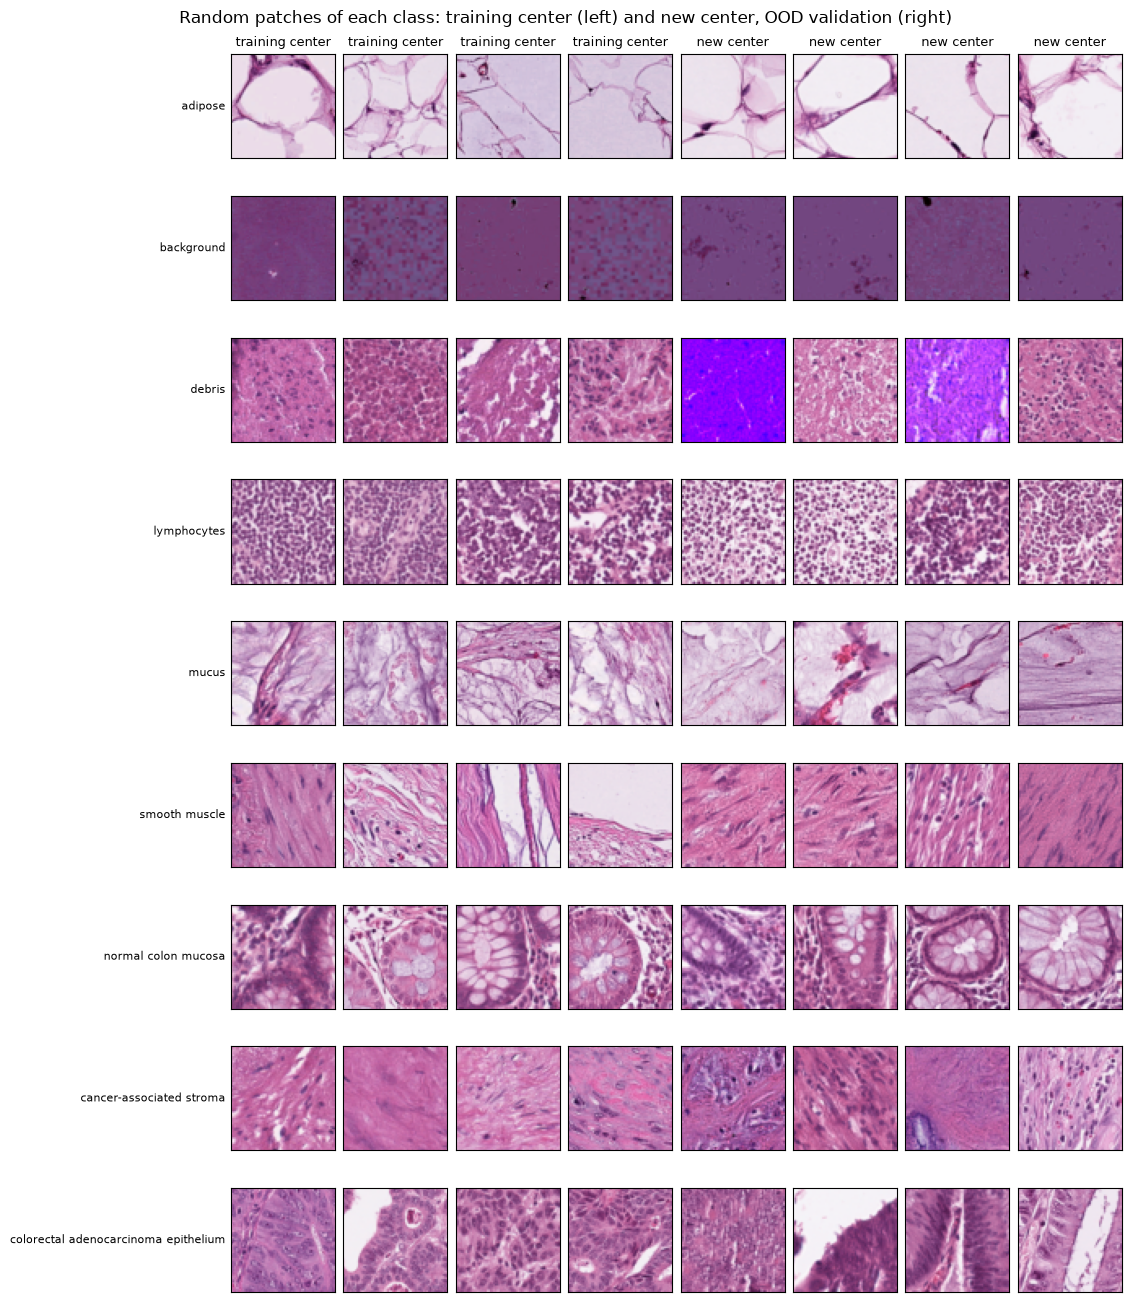

In [6]:
n = 4
rng = np.random.default_rng(seed)

fig, axs = plt.subplots(len(CLASSES), 2 * n, figsize=(2 * n * 1.4, len(CLASSES) * 1.45), constrained_layout=True)
for c, name in enumerate(CLASSES):
    for j, split in enumerate(["train", "ood_val"]):
        X, y = SPLITS[split]
        for k, i in enumerate(rng.choice(np.flatnonzero(y.numpy() == c), size=n, replace=False)):
            ax = axs[c, j * n + k]
            ax.imshow(X[i].permute(1, 2, 0).numpy())
            ax.set_xticks([])
            ax.set_yticks([])
            if c == 0:
                ax.set_title("training center" if split == "train" else "new center", fontsize=9)
    axs[c, 0].set_ylabel(name, fontsize=8, rotation=0, ha="right", va="center")

fig.suptitle("Random patches of each class: training center (left) and new center, OOD validation (right)", fontsize=12)
plt.show()

In [7]:
# Shared setup of the exploration below. Only train, id_val and ood_val are used

EDA_SPLITS = [
    "train",
    "id_val",
    "ood_val"
]

SPLIT_COLORS = {
    "train": "#2a78d6",
    "id_val": "#1baf7a",
    "ood_val": "#eb6834"
}

SPLIT_LABELS = {
    "train": "train (training center)",
    "id_val": "id_val (training center)",
    "ood_val": "ood_val (new center)"
}

SHORT_CLASSES = [
    "adipose",
    "background",
    "debris",
    "lymphocytes",
    "mucus",
    "smooth\nmuscle",
    "normal\nmucosa",
    "stroma",
    "tumor\nepithelium"
]

split_labels = {s: SPLITS[s][1].numpy() for s in EDA_SPLITS}
patch_means = {s: SPLITS[s][0].numpy().mean(axis=(2, 3)) / 255 for s in EDA_SPLITS}   # mean color of each patch: (N, 3)


def plot_per_class(features: dict[str, np.ndarray], names: list[str], title: str) -> None:
    # One row per feature: its distribution in each class, training center vs new center
    # (boxes: quartiles and median; whiskers: 5th and 95th percentiles)
    fig, axs = plt.subplots(len(names), 1, figsize=(14, 2.8 * len(names)), sharex=True)
    pos, centers = np.arange(len(CLASSES)), ["train", "ood_val"]
    for f, (ax, name) in enumerate(zip(axs, names)):
        for k, s in enumerate(centers):
            data = [features[s][split_labels[s] == c, f] for c in range(len(CLASSES))]
            ax.boxplot(data, positions=pos + 0.36 * (k - 0.5), widths=0.3, whis=(5, 95), showfliers=False,
                       patch_artist=True, boxprops=dict(facecolor=SPLIT_COLORS[s]), medianprops=dict(color="black"))
        ax.set_ylabel(name)
        ax.grid(axis="y", alpha=0.3)
    axs[-1].set_xticks(pos, SHORT_CLASSES)
    handles = [plt.Rectangle((0, 0), 1, 1, facecolor=SPLIT_COLORS[s], edgecolor="black") for s in centers]
    axs[0].legend(handles, [SPLIT_LABELS[s] for s in centers], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2,
                  frameon=False)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

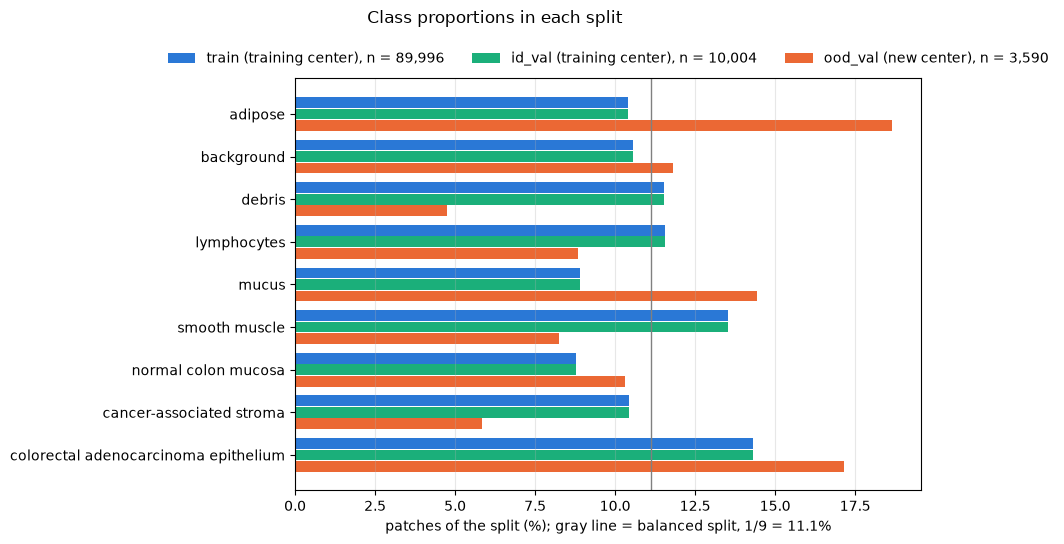

,train,id_val,ood_val,ood_val / train
adipose,10.4,10.4,18.6,1.79
background,10.6,10.6,11.8,1.12
debris,11.5,11.5,4.7,0.41
lymphocytes,11.6,11.6,8.8,0.76
mucus,8.9,8.9,14.4,1.62
smooth muscle,13.5,13.5,8.2,0.61
normal colon mucosa,8.8,8.8,10.3,1.18
cancer-associated stroma,10.4,10.4,5.8,0.56
colorectal adenocarcinoma epithelium,14.3,14.3,17.2,1.20


In [8]:
# PLOT: class proportions in each split

counts = pd.DataFrame({s: np.bincount(split_labels[s], minlength=len(CLASSES)) for s in EDA_SPLITS}, index=CLASSES)
props = 100 * counts / counts.sum()

fig, ax = plt.subplots(figsize=(10, 5.5))
pos = np.arange(len(CLASSES))
for k, s in enumerate(EDA_SPLITS):
    ax.barh(pos + 0.27 * (k - 1), props[s], height=0.25, color=SPLIT_COLORS[s],
            label=f"{SPLIT_LABELS[s]}, n = {counts[s].sum():,}")
ax.axvline(100 / len(CLASSES), color="gray", linewidth=1)
ax.set_yticks(pos, CLASSES)
ax.invert_yaxis()
ax.set_xlabel("patches of the split (%); gray line = balanced split, 1/9 = 11.1%")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
fig.suptitle("Class proportions in each split", fontsize=12)
plt.tight_layout()
plt.show()

display(props.round(1).assign(**{"ood_val / train": (props["ood_val"] / props["train"]).round(2)}))

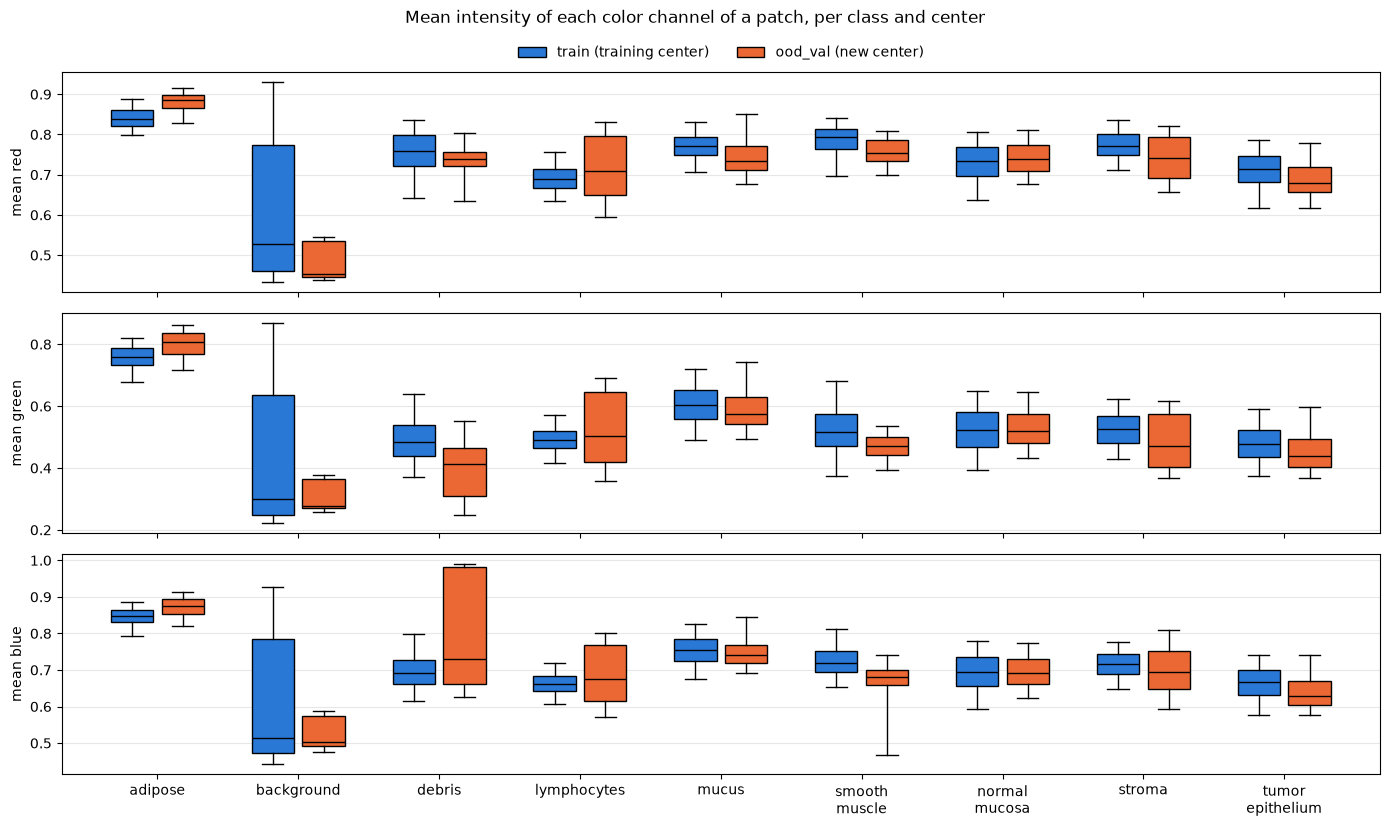

In [9]:
# PLOT: mean intensity of each color channel of a patch, per class and center

plot_per_class(patch_means, ["mean red", "mean green", "mean blue"],
               "Mean intensity of each color channel of a patch, per class and center")

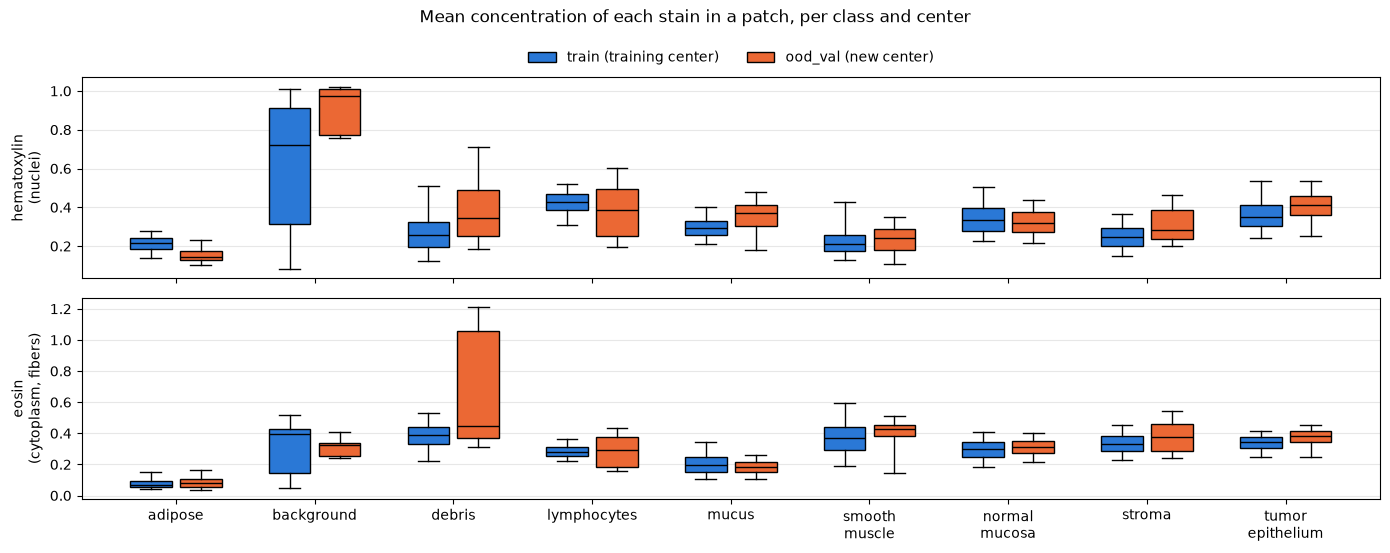

,hematoxylin: ood_val / train,eosin: ood_val / train
adipose,0.66,1.19
background,1.35,0.81
debris,1.35,1.15
lymphocytes,0.90,1.04
mucus,1.27,0.93
smooth muscle,1.16,1.14
normal colon mucosa,0.95,1.05
cancer-associated stroma,1.15,1.15
colorectal adenocarcinoma epithelium,1.17,1.13


In [10]:
# PLOT: mean amount of hematoxylin and eosin of a patch, per class and center
# Color deconvolution of skimage.color.rgb2hed, the same used by stain_jitter in Experiment 3: the optical density
# -log(intensity) of each pixel is a linear combination of the concentrations of hematoxylin, eosin and DAB

hed_from_rgb = np.linalg.inv([[0.65, 0.70, 0.29],    # hematoxylin
                              [0.07, 0.99, 0.11],    # eosin
                              [0.27, 0.57, 0.78]])   # DAB (not used in H&E staining)


def mean_optical_density(X: torch.Tensor, chunk: int = 5_000) -> np.ndarray:
    # Mean optical density of each color channel of every patch: (N, 3)
    return torch.cat([-torch.log(to_unit(X[i:i + chunk]).clamp(min=1e-6)).mean(dim=(2, 3)).cpu()
                      for i in range(0, len(X), chunk)]).numpy()


stains = {s: mean_optical_density(SPLITS[s][0]) @ hed_from_rgb for s in ["train", "ood_val"]}
plot_per_class(stains, ["hematoxylin\n(nuclei)", "eosin\n(cytoplasm, fibers)"],
               "Mean concentration of each stain in a patch, per class and center")

# Relative change of the median concentration of each stain in the new center
display(pd.DataFrame({stain: [np.median(stains["ood_val"][split_labels["ood_val"] == c, k]) /
                              np.median(stains["train"][split_labels["train"] == c, k]) for c in range(len(CLASSES))]
                      for k, stain in enumerate(["hematoxylin: ood_val / train", "eosin: ood_val / train"])},
                     index=CLASSES).round(2))

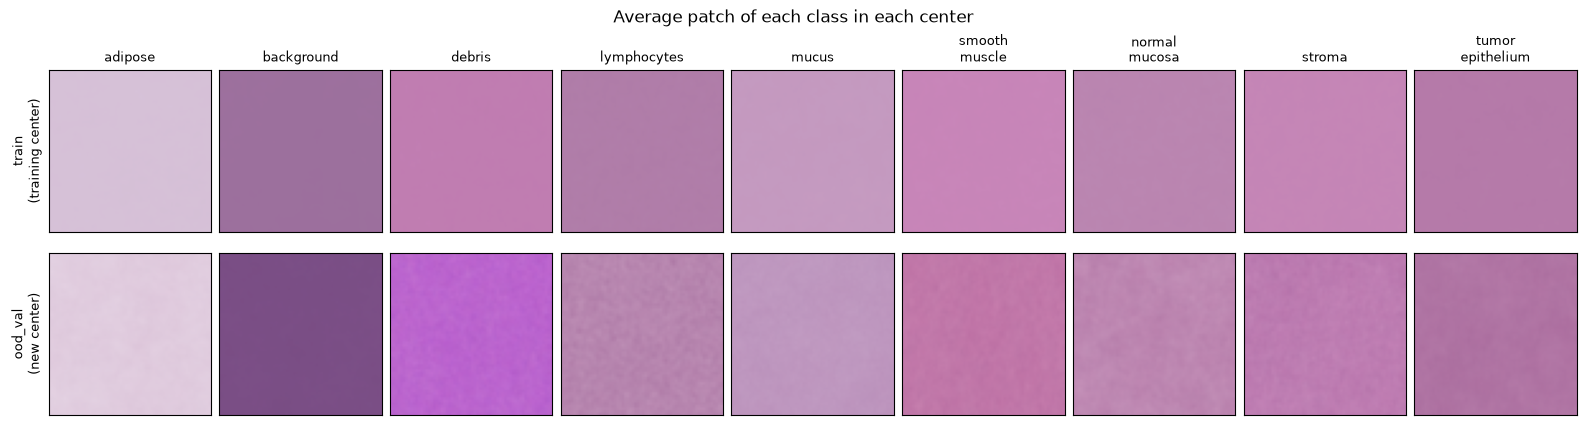

In [11]:
# PLOT: average patch of each class in each center

fig, axs = plt.subplots(2, len(CLASSES), figsize=(1.75 * len(CLASSES), 4.2), constrained_layout=True)
for r, s in enumerate(["train", "ood_val"]):
    X, y = SPLITS[s]
    for c in range(len(CLASSES)):
        axs[r, c].imshow(X[y == c].numpy().mean(axis=0).transpose(1, 2, 0) / 255)
        axs[r, c].set_xticks([])
        axs[r, c].set_yticks([])
        axs[0, c].set_title(SHORT_CLASSES[c], fontsize=9)
    axs[r, 0].set_ylabel(SPLIT_LABELS[s].replace(" (", "\n("), fontsize=9)
fig.suptitle("Average patch of each class in each center", fontsize=12)
plt.show()

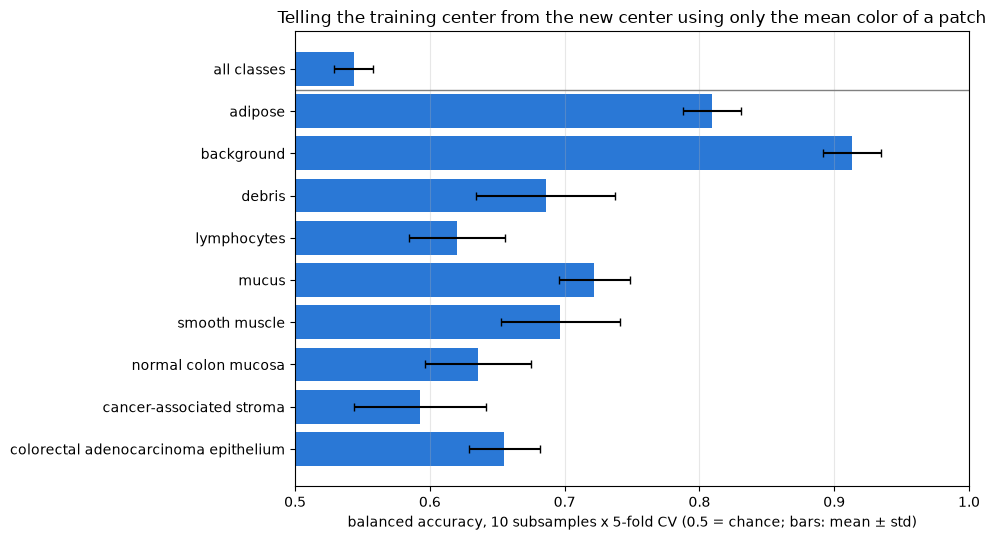

,bal_acc_mean,bal_acc_std,patches_per_center
all classes,0.543,0.015,3590
adipose,0.809,0.021,669
background,0.913,0.022,424
debris,0.686,0.052,170
lymphocytes,0.620,0.036,317
mucus,0.722,0.027,518
smooth muscle,0.697,0.044,296
normal colon mucosa,0.636,0.039,370
cancer-associated stroma,0.593,0.049,210
colorectal adenocarcinoma epithelium,0.655,0.026,616


In [12]:
# PLOT: telling the training center from the new center using only the mean color of a patch
# Train is subsampled with the same number of patches of each class as ood_val
# Each repetition draws a new subsample and new folds

N_REPEATS = 10


def center_scores(colors_train: np.ndarray, colors_ood: np.ndarray, cv_seed: int) -> np.ndarray:
    # Balanced accuracy on each of the 5 folds of a logistic regression that tells train (0) from ood_val (1)
    X = np.vstack([colors_train, colors_ood])
    y = np.r_[np.zeros(len(colors_train)), np.ones(len(colors_ood))]
    cv = StratifiedKFold(5, shuffle=True, random_state=cv_seed)
    clf = make_pipeline(StandardScaler(), LogisticRegression())
    return cross_val_score(clf, X, y, cv=cv, scoring="balanced_accuracy")


ood_counts = np.bincount(split_labels["ood_val"], minlength=len(CLASSES))
scores = {name: [] for name in ["all classes", *CLASSES]}
for rep in range(N_REPEATS):
    rng = np.random.default_rng(seed + rep)
    matched = np.concatenate([rng.choice(np.flatnonzero(split_labels["train"] == c), size=n, replace=False)
                              for c, n in enumerate(ood_counts)])
    colors, classes = patch_means["train"][matched], split_labels["train"][matched]
    scores["all classes"].append(center_scores(colors, patch_means["ood_val"], seed + rep))
    for c, name in enumerate(CLASSES):
        ood_colors = patch_means["ood_val"][split_labels["ood_val"] == c]
        scores[name].append(center_scores(colors[classes == c], ood_colors, seed + rep))

center_df = pd.DataFrame({"bal_acc_mean": [np.mean(v) for v in scores.values()],
                          "bal_acc_std": [np.std(v) for v in scores.values()],
                          "patches_per_center": [ood_counts.sum(), *ood_counts]}, index=list(scores))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(center_df.index, center_df["bal_acc_mean"] - 0.5, left=0.5, xerr=center_df["bal_acc_std"], capsize=3,
        color=SPLIT_COLORS["train"])
ax.axhline(0.5, color="gray", linewidth=1)
ax.set_xlim(0.5, 1.0)
ax.invert_yaxis()
ax.set_xlabel(f"balanced accuracy, {N_REPEATS} subsamples x 5-fold CV (0.5 = chance; bars: mean ± std)")
ax.grid(axis="x", alpha=0.3)
ax.set_title("Telling the training center from the new center using only the mean color of a patch", fontsize=12)
plt.tight_layout()
plt.show()

display(center_df.round(3))

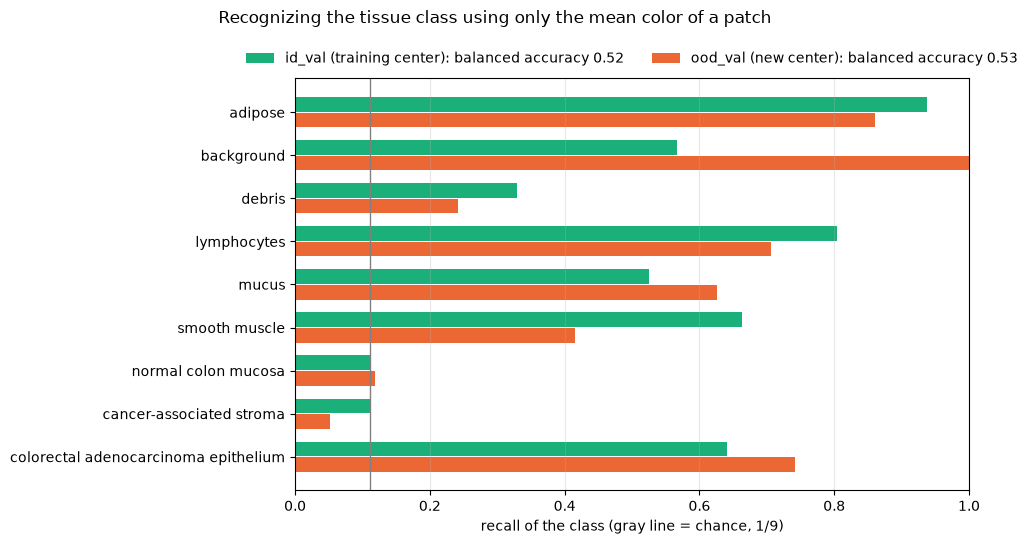

,id_val,ood_val
adipose,0.94,0.86
background,0.57,1.00
debris,0.33,0.24
lymphocytes,0.80,0.71
mucus,0.53,0.63
smooth muscle,0.66,0.42
normal colon mucosa,0.11,0.12
cancer-associated stroma,0.11,0.05
colorectal adenocarcinoma epithelium,0.64,0.74


In [13]:
# PLOT: recognizing the tissue class using only the mean color of a patch, in each center
# A logistic regression trained on the mean color of the train patches, evaluated on both validation splits

color_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1_000))
color_clf.fit(patch_means["train"], split_labels["train"])
recalls = pd.DataFrame({s: confusion_matrix(split_labels[s], color_clf.predict(patch_means[s]), normalize="true")
                        .diagonal() for s in ["id_val", "ood_val"]}, index=CLASSES)

fig, ax = plt.subplots(figsize=(10, 5.5))
pos = np.arange(len(CLASSES))
for k, s in enumerate(recalls):
    ax.barh(pos + 0.36 * (k - 0.5), recalls[s], height=0.34, color=SPLIT_COLORS[s],
            label=f"{SPLIT_LABELS[s]}: balanced accuracy {recalls[s].mean():.2f}")
ax.axvline(1 / len(CLASSES), color="gray", linewidth=1)
ax.set_yticks(pos, CLASSES)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("recall of the class (gray line = chance, 1/9)")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.suptitle("Recognizing the tissue class using only the mean color of a patch", fontsize=12)
plt.tight_layout()
plt.show()

display(recalls.round(2))

> **Question.** (1.0 pt)
>
> What are your findings? Describe the task, the balance of the classes, and how the two centers differ. Which
> properties of the patches seem to be stable across centers, and which change from one center to the other?
>
> Based only on this exploration, predict which architecture, MLP or CNN, is more likely to rely on properties that
> change between centers, and why.

A tarefa consiste em classificar cada patch RGB de 64 × 64 pixels de uma lâmina histológica colorretal em uma das nove classes do PathMNIST. No treino e na validação do mesmo centro (ID), as proporções das classes são praticamente idênticas e variam de 8,8% a 14,3%. Na validação do novo centro (OOD), a distribuição é mais desigual, com a proporção de tecido adiposo subindo de 10,4% no treino para 18,6%, enquanto a de detritos cai de 11,5% para 4,7%.

Algumas características morfológicas parecem se preservar nos dois centros. Nos patches de tecido adiposo, observam-se grandes espaços claros delimitados por bordas finas. Nos de linfócitos, distinguem-se agrupamentos densos de pequenos núcleos e, nos de músculo liso, feixes alongados em diferentes orientações. Ao comparar amostras da mesma classe entre os dois centros, porém, observam-se diferenças de coloração. No novo centro, a mediana estimada de hematoxilina é 35% maior nos detritos e 34% menor no tecido adiposo em relação ao treino.

Essas diferenças ajudam a identificar o centro de origem, mas sua intensidade e direção dependem da classe. Quando as classes são analisadas separadamente, uma regressão logística que usa apenas a cor média RGB alcança acurácia balanceada de 59,3% no estroma a 91,3% no fundo, com 80,9% no tecido adiposo. Quando as nove classes são reunidas, mantendo a mesma proporção de cada classe nos dois centros, a acurácia balanceada fica em 54,3%, próxima dos 50% esperados ao acaso. Isso sugere que uma diferença de cor perceptível para determinado tecido pode ser pouco informativa sobre o centro de origem quando se consideram todos os tecidos em conjunto.

A cor média também ajuda a prever a classe do tecido. Usando apenas os três valores médios de RGB, o classificador alcança 52% de acurácia balanceada em ID e 53% em OOD, acima dos 11,1% esperados ao acaso para nove classes. A proximidade dessas médias esconde mudanças importantes por classe. Do centro de treino para o novo centro, o recall do músculo liso cai de 66% para 42%, enquanto o da classe de fundo sobe de 57% para 100%.

Com base nessa exploração, nossa hipótese é que a MLP seja mais propensa que a CNN a depender da tonalidade global. Ao calcular a média dos patches de cada classe, obtemos imagens quase uniformes. Isso sugere que estruturas como bordas e núcleos aparecem em posições variadas e se diluem na média, enquanto a tonalidade global permanece visível. Como a MLP atribui pesos próprios a cada posição, ela precisa aprender a reconhecer uma estrutura em diferentes regiões da imagem. Agregar as intensidades dos pixels oferece uma alternativa mais simples, e os 52% de acurácia balanceada em ID mostram que essa informação já é útil para prever o tecido durante o treino. A CNN, por compartilhar filtros entre posições, pode reconhecer a mesma borda ou textura em diferentes regiões. Por isso, esperamos que ela aproveite melhor os padrões morfológicos que parecem se preservar entre os centros, embora também possa usar a cor.

---

## Training utilities

All the experiments train and evaluate models with the same four functions, which you will implement in the next
cell. The hands-on of Lecture 18 contains a training loop that you can start from.

> **Implementation.** (1.0 pt)
>
> Implement the four functions below, keeping their names, arguments and return values, since the rest of the notebook
> uses them:
>
> - `make_loader(split, batch_size, shuffle, shuffle_seed)` returns a `DataLoader` over the patches and labels of
>   `SPLITS[split]`. When `shuffle=True`, the order must be **reproducible**: shuffle with a `torch.Generator` seeded
>   with `shuffle_seed`.
> - `predict(model, loader, preprocess, input_fn=None)` returns the predicted classes and the true labels of a whole
>   loader, as two NumPy arrays. Each batch goes through `preprocess` and then, if it is given, through `input_fn`
>   (used in Experiment 2). The model must be in evaluation mode, and no gradients are needed.
> - `evaluate(model, loader, preprocess, input_fn=None)` returns `{"acc": ..., "bal_acc": ...}`, the accuracy and the
>   balanced accuracy of the predictions of `predict`.
> - `fit(model, train_loader, val_loader, optimizer, n_epochs, preprocess, augment=None, verbose=True)` trains the
>   model with `nn.CrossEntropyLoss` (all models output **9 logits** per patch, and the loss applies the softmax).
>   Each training batch goes through `preprocess(x, augment)`. After every epoch, `fit` evaluates the model on
>   `val_loader` and keeps a copy of the weights of the epoch with the best **ID validation balanced accuracy** (early
>   stopping). At the end it restores those weights, so the model used afterwards is the one of the best epoch. It
>   returns a dictionary `history` with:
>   - `"train_loss"`, `"train_acc"`, `"val_acc"`, `"val_bal_acc"`: lists with one value per epoch;
>   - `"best_epoch"`: the epoch whose weights were kept, counting from 1;
>   - `"train_time"`: the total training time, in seconds.
>
>   With `verbose=True`, it prints the metrics of each epoch.
>
> Model selection inside `fit` must use only the ID validation split. Run the sanity check below before starting the
> experiments.

The cell after your implementation is already complete:
- `report` evaluates a trained model on the ID and the OOD validation splits and stores the results in `RESULTS`,
  which you will use in the Summary table;
- `plot_histories` plots the histories returned by `fit`.

In [14]:
def make_loader(split: str, batch_size: int = 512, shuffle: bool = False, shuffle_seed: int = seed) -> DataLoader:
    # DataLoader over the uint8 patches and labels of SPLITS[split]. The shuffled order is fixed by shuffle_seed.
    X, y = SPLITS[split]
    generator = torch.Generator().manual_seed(shuffle_seed) if shuffle else None
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=shuffle, generator=generator,
                      pin_memory=(DEVICE == "cuda"))


def predict(model: nn.Module, loader: DataLoader, preprocess: Preprocess, input_fn=None) -> tuple[np.ndarray, np.ndarray]:
    # Predicted classes (argmax of the logits) and true labels of the whole loader, as NumPy arrays.
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x = preprocess(x)
            if input_fn is not None:
                x = input_fn(x)
            all_preds.append(model(x).argmax(dim=1).cpu())
            all_labels.append(y)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()


def evaluate(model: nn.Module, loader: DataLoader, preprocess: Preprocess, input_fn=None) -> dict[str, float]:
    # Accuracy and balanced accuracy (mean of the per-class recalls) of the predictions of predict().
    preds, labels = predict(model, loader, preprocess, input_fn)
    return {"acc": float((preds == labels).mean()), "bal_acc": float(balanced_accuracy_score(labels, preds))}


def fit(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, optimizer: optim.Optimizer,
        n_epochs: int, preprocess: Preprocess, augment=None, verbose: bool = True) -> dict:
    # Trains with cross-entropy and keeps the weights of the epoch with the best ID validation balanced accuracy.
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "val_acc": [], "val_bal_acc": [], "best_epoch": None,
               "train_time": None}
    best_bal_acc, best_state = -1.0, None
    start = time.time()

    for epoch in range(1, n_epochs + 1):
        model.train()
        loss_sum, n_correct, n_seen = 0.0, 0, 0
        for x, y in train_loader:
            x = preprocess(x, augment)
            y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            # Weighted by the batch size, so that a smaller last batch does not distort the epoch average.
            loss_sum += loss.item() * len(y)
            n_correct += (logits.argmax(dim=1) == y).sum().item()
            n_seen += len(y)

        val = evaluate(model, val_loader, preprocess)
        history["train_loss"].append(loss_sum / n_seen)
        history["train_acc"].append(n_correct / n_seen)
        history["val_acc"].append(val["acc"])
        history["val_bal_acc"].append(val["bal_acc"])

        if val["bal_acc"] > best_bal_acc:                 # early stopping on the ID validation only
            best_bal_acc = val["bal_acc"]
            best_state = copy.deepcopy(model.state_dict())
            history["best_epoch"] = epoch

        if verbose:
            print(f"epoch {epoch:2d}/{n_epochs} | train loss {history['train_loss'][-1]:.4f} "
                  f"| train acc {history['train_acc'][-1]:.3f} | val acc {val['acc']:.3f} "
                  f"| val bal. acc {val['bal_acc']:.3f}{'  *' if history['best_epoch'] == epoch else ''}")

    model.load_state_dict(best_state)
    history["train_time"] = time.time() - start
    if verbose:
        print(f"best epoch: {history['best_epoch']} (val bal. acc {best_bal_acc:.3f}) "
              f"| training time: {history['train_time']:.0f} s")
    return history

In [15]:
RESULTS: dict[str, dict] = {}   # one row per trained model, filled by report()
MODELS: dict[str, tuple] = {}   # name -> (model, Preprocess used to evaluate it)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def report(name: str, model: nn.Module, preprocess: Preprocess, history: dict | None = None) -> dict:
    # ID and OOD validation metrics of a trained model, stored in RESULTS.
    id_m = evaluate(model, make_loader("id_val"), preprocess)
    ood_m = evaluate(model, make_loader("ood_val"), preprocess)
    RESULTS[name] = {
        "params": count_params(model),
        "train_time_s": round(history["train_time"]) if history else None,
        "id_acc": id_m["acc"], "id_bal_acc": id_m["bal_acc"],
        "ood_acc": ood_m["acc"], "ood_bal_acc": ood_m["bal_acc"],
        "gap_bal_acc": id_m["bal_acc"] - ood_m["bal_acc"],
    }
    MODELS[name] = (model, preprocess)
    r = RESULTS[name]
    print(f"{name}: ID bal. acc {r['id_bal_acc']:.3f} | OOD bal. acc {r['ood_bal_acc']:.3f} | gap {r['gap_bal_acc']:+.3f} "
          f"| ID acc {r['id_acc']:.3f} | OOD acc {r['ood_acc']:.3f}")
    return r


def plot_histories(histories: dict[str, dict], title: str = "") -> None:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        epochs = range(1, len(h["train_loss"]) + 1)
        axs[0].plot(epochs, h["train_loss"], color=color, label=name)
        axs[1].plot(epochs, h["train_acc"], "--", color=color, alpha=0.7)
        axs[1].plot(epochs, h["val_acc"], color=color, label=name)
        axs[2].plot(epochs, h["val_bal_acc"], color=color, label=name)
        best = h["best_epoch"]
        axs[2].scatter(best, h["val_bal_acc"][best - 1], marker="*", s=150, color=color, edgecolor="black", zorder=5)
    titles = ["training loss", "accuracy (dashed = train, solid = ID val)", "ID val balanced accuracy (star = kept epoch)"]
    for ax, t in zip(axs, titles):
        ax.set_title(t)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=len(histories),
               frameon=False)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()

In [16]:
# Sanity check of your implementation, with a tiny model and 2,000 training patches (a few seconds).
torch.manual_seed(seed)
check_model = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(3 * 64 * 64, len(CLASSES))).to(DEVICE)
check_train = DataLoader(TensorDataset(X_train[:2_000], y_train[:2_000]), batch_size=128, shuffle=True)
check_val = DataLoader(TensorDataset(X_id_val[:1_000], y_id_val[:1_000]), batch_size=512)
check_history = fit(check_model, check_train, check_val, optim.Adam(check_model.parameters(), lr=1e-3), 3, rgb,
                    verbose=False)

preds, labels = predict(check_model, check_val, rgb)
assert preds.shape == labels.shape == (1_000,), "predict must return one prediction and one label per patch"
assert np.array_equal(preds, predict(check_model, check_val, rgb)[0]), "predict must put the model in evaluation mode"
for key in ["train_loss", "train_acc", "val_acc", "val_bal_acc"]:
    assert len(check_history[key]) == 3, f'history["{key}"] must have one value per epoch'
assert check_history["train_time"] is not None, 'history["train_time"] is missing'
best = check_history["best_epoch"]
assert best in (1, 2, 3) and check_history["val_bal_acc"][best - 1] == max(check_history["val_bal_acc"]), \
    "best_epoch must be the epoch with the best ID validation balanced accuracy, counting from 1"
assert abs(evaluate(check_model, check_val, rgb)["bal_acc"] - check_history["val_bal_acc"][best - 1]) < 1e-6, \
    "fit must restore the weights of the best epoch"
first_batch = lambda: next(iter(make_loader("train", batch_size=8, shuffle=True)))[1]
assert torch.equal(first_batch(), first_batch()), "the shuffled order must be reproducible (use shuffle_seed)"
print("All checks passed.")

All checks passed.


---

## Experiment 1: Is the Convolutional Structure Necessary?

A CNN builds three assumptions into the network:
- **locality**: each unit of a convolutional layer looks only at a small neighborhood of the previous layer;
- **weight sharing**: the same filter is applied at every position, so a pattern is detected wherever it appears;
- **hierarchy**: deeper layers combine the patterns of earlier ones, over larger and larger regions.

An MLP applied to the flattened pixels has none of them: each of the 64×64×3 = 12,288 inputs has its own weight in
every unit of the first layer, and any spatial relationship must be learned from the data. In Lecture 18, the same
MLP that worked on Fashion-MNIST (centered, aligned objects) failed on CIFAR-10 (objects anywhere in the image),
while a CNN with 5 times fewer parameters did much better. Are tissue patches closer to the first case or to the
second?

This comparison also illustrates that **the number of parameters does not determine generalization**: the first
layer of the MLP alone has about 65 times more parameters than the whole SmallCNN.

> **Question:**
>
> Does the spatial inductive bias of a CNN improve in-distribution performance *and* generalization to a new
> clinical center, compared with an MLP with many more parameters trained under the same conditions?

> **Hypothesis:**
>
> A tissue class is defined by local patterns (the shape, size and density of nuclei and fibers, the arrangement of
> glands and cells), which can appear at any position of the patch and are the same in every center. A SmallCNN, which
> detects local patterns anywhere with shared filters, will therefore reach a **higher balanced accuracy than the MLP
> on both the ID and the OOD validation splits**, and a **smaller ID–OOD gap**, despite having more than 60 times fewer
> parameters.
> The hypothesis is contradicted if the MLP matches or beats the CNN on the OOD validation balanced accuracy, or if the
> gap of the CNN is not smaller than the gap of the MLP.

> **Baseline:**
>
> A classifier that always predicts the same class has balanced accuracy 1/9 ≈ 0.11.

In [17]:
class MLP(nn.Module):
    # Fully connected network on the flattened patch: no spatial inductive bias.

    def __init__(self, input_size: int, hidden_sizes: list[int], n_classes: int = 9, dropout: float = 0.0) -> None:
        super().__init__()
        layers, size = [nn.Flatten()], input_size
        for hidden in hidden_sizes:
            layers += [nn.Linear(size, hidden), nn.ReLU(), nn.Dropout(dropout)]
            size = hidden
        self.net = nn.Sequential(*layers, nn.Linear(size, n_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class SmallCNN(nn.Module):
    # Small convolutional network: locality, weight sharing and hierarchy.

    def __init__(self, channels: tuple[int, ...] = (32, 64, 128), n_classes: int = 9) -> None:
        super().__init__()
        layers, in_channels = [], 3
        for out_channels in channels:
            layers += [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1), nn.BatchNorm2d(out_channels),
                       nn.ReLU(), nn.MaxPool2d(2)]
            in_channels = out_channels
        self.net = nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(in_channels, n_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

In [18]:
mlp = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256])
cnn = SmallCNN()

print(f"MLP parameters      : {count_params(mlp):>12,}")
print(f"SmallCNN parameters : {count_params(cnn):>12,}")
print("Both models receive the same standardized 64x64x3 patches and are trained with the same loop.")

MLP parameters      :    6,425,609
SmallCNN parameters :       94,857
Both models receive the same standardized 64x64x3 patches and are trained with the same loop.


In [19]:
id_val_loader = make_loader("id_val")

# Hint: the comparison is fair if both models are trained under the same conditions (same optimizer, learning rate
# and number of epochs), or if each one is given the chance to perform at its best (tuning each one separately on the
# ID validation split). If the CNN beats the MLP but they were trained very differently, it is hard to argue that the
# architecture is the cause.

# Both models are trained under the same conditions: Adam, the same learning rate and the same number of epochs,
# keeping the epoch with the best ID validation balanced accuracy. Each training creates its own training loader
# with the same shuffle seed, so every model sees the training patches in the same order.
learning_rate = 1e-3
n_epochs = 30
dropout = 0.3   # only the MLP has dropout layers

In [20]:
torch.manual_seed(seed)
mlp = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256], dropout=dropout).to(DEVICE)
mlp_optimizer = optim.Adam(mlp.parameters(), lr=learning_rate)

mlp_history = fit(mlp, make_loader("train", batch_size=128, shuffle=True), id_val_loader, mlp_optimizer, n_epochs, rgb)
report("MLP (Exp. 1)", mlp, rgb, mlp_history);

epoch  1/30 | train loss 1.2874 | train acc 0.497 | val acc 0.536 | val bal. acc 0.524  *


epoch  2/30 | train loss 1.0954 | train acc 0.575 | val acc 0.624 | val bal. acc 0.609  *


epoch  3/30 | train loss 1.0214 | train acc 0.603 | val acc 0.627 | val bal. acc 0.614  *


epoch  4/30 | train loss 0.9907 | train acc 0.616 | val acc 0.628 | val bal. acc 0.634  *


epoch  5/30 | train loss 0.9591 | train acc 0.629 | val acc 0.639 | val bal. acc 0.632


epoch  6/30 | train loss 0.9429 | train acc 0.636 | val acc 0.636 | val bal. acc 0.630


... (20 outputs left out)

epoch 27/30 | train loss 0.6226 | train acc 0.780 | val acc 0.661 | val bal. acc 0.661


epoch 28/30 | train loss 0.6169 | train acc 0.783 | val acc 0.657 | val bal. acc 0.658


epoch 29/30 | train loss 0.5972 | train acc 0.790 | val acc 0.667 | val bal. acc 0.665  *


epoch 30/30 | train loss 0.5863 | train acc 0.794 | val acc 0.657 | val bal. acc 0.661
best epoch: 29 (val bal. acc 0.665) | training time: 110 s
MLP (Exp. 1): ID bal. acc 0.665 | OOD bal. acc 0.550 | gap +0.115 | ID acc 0.667 | OOD acc 0.612


In [21]:
torch.manual_seed(seed)
cnn = SmallCNN().to(DEVICE)
cnn_optimizer = optim.Adam(cnn.parameters(), lr=learning_rate)

cnn_history = fit(cnn, make_loader("train", batch_size=128, shuffle=True), id_val_loader, cnn_optimizer, n_epochs, rgb)
report("SmallCNN (Exp. 1)", cnn, rgb, cnn_history);

epoch  1/30 | train loss 0.4363 | train acc 0.861 | val acc 0.780 | val bal. acc 0.778  *


epoch  2/30 | train loss 0.1884 | train acc 0.939 | val acc 0.840 | val bal. acc 0.841  *


epoch  3/30 | train loss 0.1431 | train acc 0.954 | val acc 0.918 | val bal. acc 0.911  *


epoch  4/30 | train loss 0.1187 | train acc 0.962 | val acc 0.944 | val bal. acc 0.941  *


epoch  5/30 | train loss 0.1053 | train acc 0.966 | val acc 0.958 | val bal. acc 0.959  *


epoch  6/30 | train loss 0.0917 | train acc 0.970 | val acc 0.958 | val bal. acc 0.957


... (21 outputs left out)

epoch 28/30 | train loss 0.0300 | train acc 0.990 | val acc 0.987 | val bal. acc 0.988  *


epoch 29/30 | train loss 0.0237 | train acc 0.993 | val acc 0.987 | val bal. acc 0.986


epoch 30/30 | train loss 0.0238 | train acc 0.992 | val acc 0.938 | val bal. acc 0.945
best epoch: 28 (val bal. acc 0.988) | training time: 393 s


SmallCNN (Exp. 1): ID bal. acc 0.988 | OOD bal. acc 0.884 | gap +0.104 | ID acc 0.987 | OOD acc 0.888


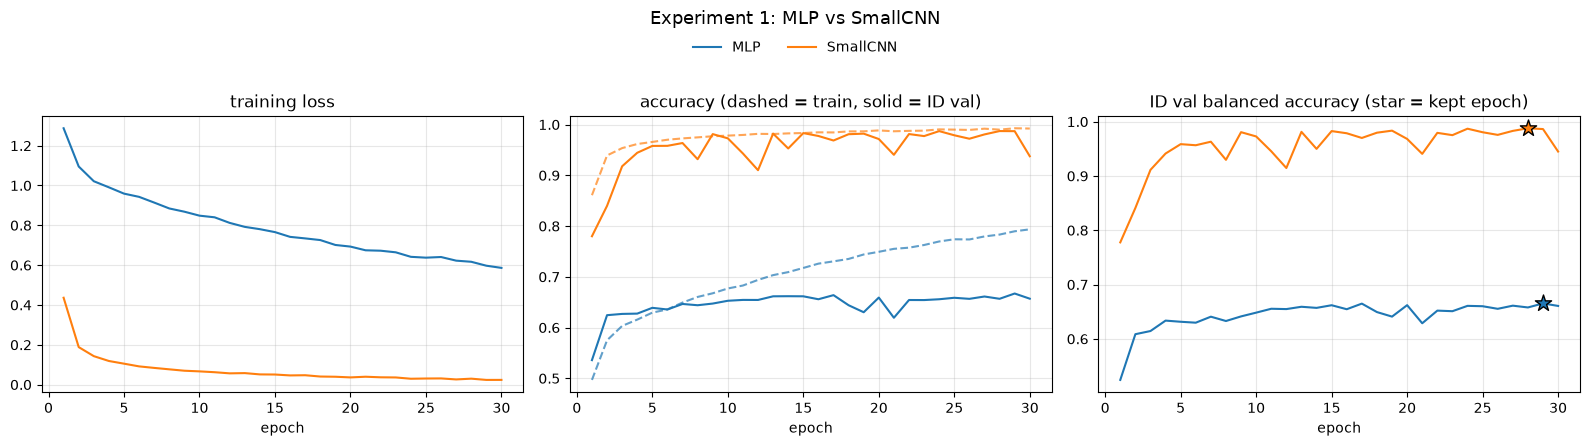

In [22]:
# PLOT: learning curves of both models

plot_histories({"MLP": mlp_history, "SmallCNN": cnn_history}, "Experiment 1: MLP vs SmallCNN")

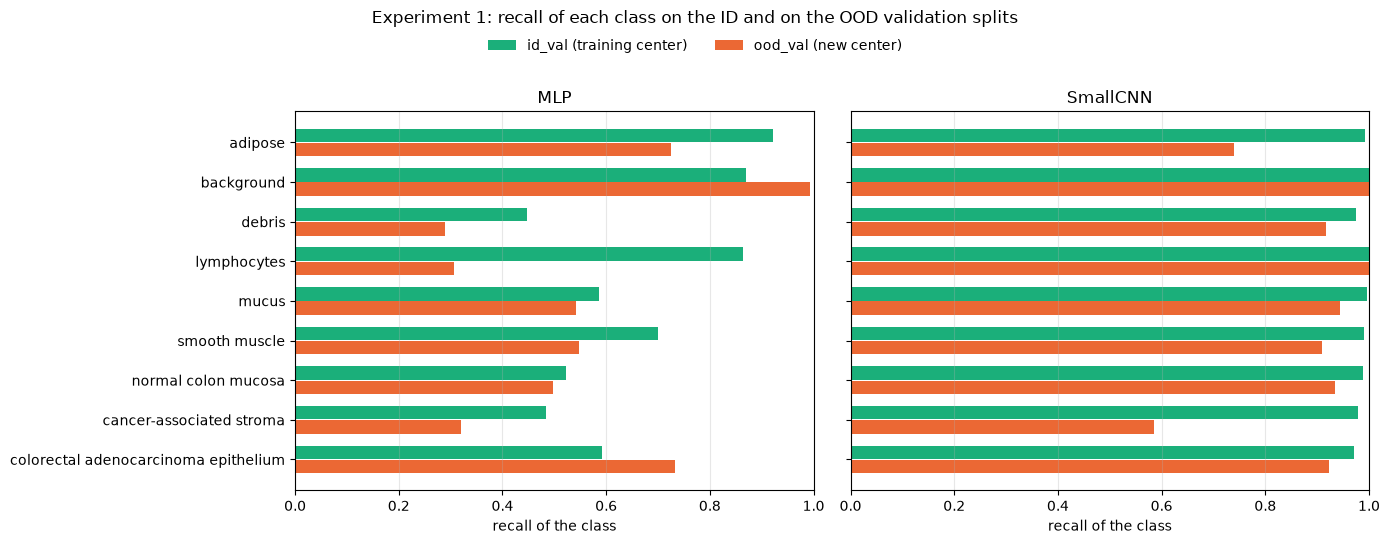

,MLP id_val,MLP ood_val,SmallCNN id_val,SmallCNN ood_val,MLP drop,SmallCNN drop
adipose,0.92,0.72,0.99,0.74,0.20,0.25
background,0.87,0.99,1.00,1.00,-0.12,-0.00
debris,0.45,0.29,0.98,0.92,0.16,0.06
lymphocytes,0.86,0.31,1.00,1.00,0.56,-0.00
mucus,0.59,0.54,1.00,0.94,0.04,0.05
smooth muscle,0.70,0.55,0.99,0.91,0.15,0.08
normal colon mucosa,0.52,0.50,0.99,0.94,0.03,0.05
cancer-associated stroma,0.48,0.32,0.98,0.59,0.17,0.39
colorectal adenocarcinoma epithelium,0.59,0.73,0.97,0.92,-0.14,0.05


In [23]:
# PLOT: recall of each class on the ID and on the OOD validation splits

def confusion(model: nn.Module, split: str, preprocess: Preprocess = rgb) -> np.ndarray:
    # Confusion matrix normalized by row: entry (i, j) is the fraction of the patches of class i predicted as j
    preds, labels = predict(model, make_loader(split), preprocess)
    return confusion_matrix(labels, preds, labels=range(len(CLASSES)), normalize="true")


exp1_models = {"MLP": mlp, "SmallCNN": cnn}
exp1_confusions = {(name, s): confusion(model, s) for name, model in exp1_models.items() for s in ["id_val", "ood_val"]}
exp1_recalls = pd.DataFrame({f"{name} {s}": cm.diagonal() for (name, s), cm in exp1_confusions.items()}, index=CLASSES)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
pos = np.arange(len(CLASSES))
for ax, name in zip(axs, exp1_models):
    for k, s in enumerate(["id_val", "ood_val"]):
        ax.barh(pos + 0.36 * (k - 0.5), exp1_recalls[f"{name} {s}"], height=0.34, color=SPLIT_COLORS[s],
                label=SPLIT_LABELS[s])
    ax.set_title(name)
    ax.set_xlim(0, 1)
    ax.set_xlabel("recall of the class")
    ax.grid(axis="x", alpha=0.3)
axs[0].set_yticks(pos, CLASSES)
axs[0].invert_yaxis()
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
fig.suptitle("Experiment 1: recall of each class on the ID and on the OOD validation splits", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

display(exp1_recalls.assign(**{f"{name} drop": exp1_recalls[f"{name} id_val"] - exp1_recalls[f"{name} ood_val"]
                               for name in exp1_models}).round(2))

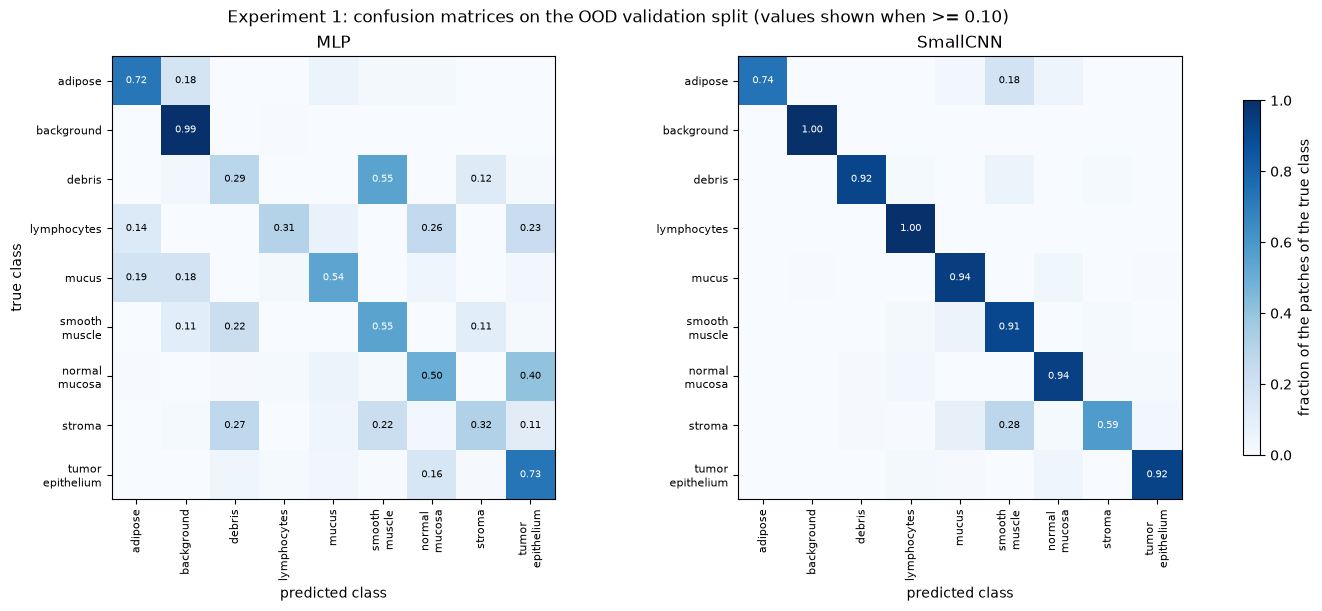

In [24]:
# PLOT: confusion matrices on the OOD validation split

fig, axs = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, name in zip(axs, exp1_models):
    cm = exp1_confusions[(name, "ood_val")]
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i, j in zip(*np.nonzero(cm >= 0.1)):                   # only the cells that hold at least 10% of a class
        color = "white" if cm[i, j] > 0.5 else "black"
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color=color)
    ax.set_xticks(range(len(CLASSES)), SHORT_CLASSES, rotation=90, fontsize=8)
    ax.set_yticks(range(len(CLASSES)), SHORT_CLASSES, fontsize=8)
    ax.set_xlabel("predicted class")
    ax.set_title(name)
axs[0].set_ylabel("true class")
fig.colorbar(im, ax=axs, shrink=0.8, label="fraction of the patches of the true class")
fig.suptitle("Experiment 1: confusion matrices on the OOD validation split (values shown when >= 0.10)", fontsize=12)
plt.show()

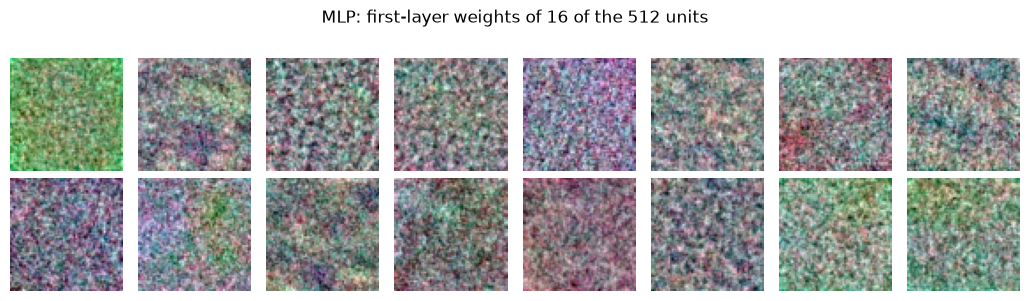

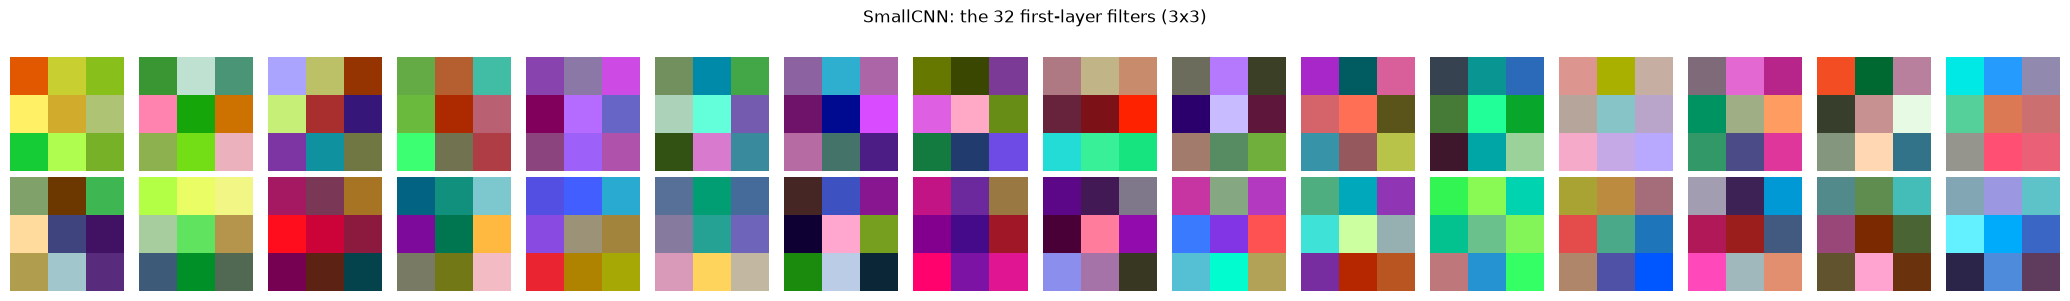

In [25]:
# PLOT: first-layer weights of the MLP (as 64x64x3 images) and first-layer filters of the CNN (3x3x3)

def show_weights(weights: torch.Tensor, n_cols: int, title: str) -> None:
    # One image per unit (n_units, 3, H, W), each rescaled to [0, 1] on its own, so that its colors show the
    # relative weight of the red, green and blue inputs.
    w = weights.detach().cpu()
    lo, hi = w.amin(dim=(1, 2, 3), keepdim=True), w.amax(dim=(1, 2, 3), keepdim=True)
    w = (w - lo) / (hi - lo)
    n_rows = int(np.ceil(len(w) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(1.3 * n_cols, 1.3 * n_rows + 0.5), squeeze=False)
    for ax in axs.flat:
        ax.axis("off")
    for ax, img in zip(axs.flat, w):
        ax.imshow(img.permute(1, 2, 0).numpy())
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


show_weights(mlp.net[1].weight[:16].view(-1, 3, 64, 64), 8, "MLP: first-layer weights of 16 of the 512 units")
show_weights(cnn.net[0].weight, 16, "SmallCNN: the 32 first-layer filters (3x3)")

MLP, PCA: 60 patches outside the view, 60 of them from ood_val


SmallCNN, PCA: 80 patches outside the view, 72 of them from ood_val


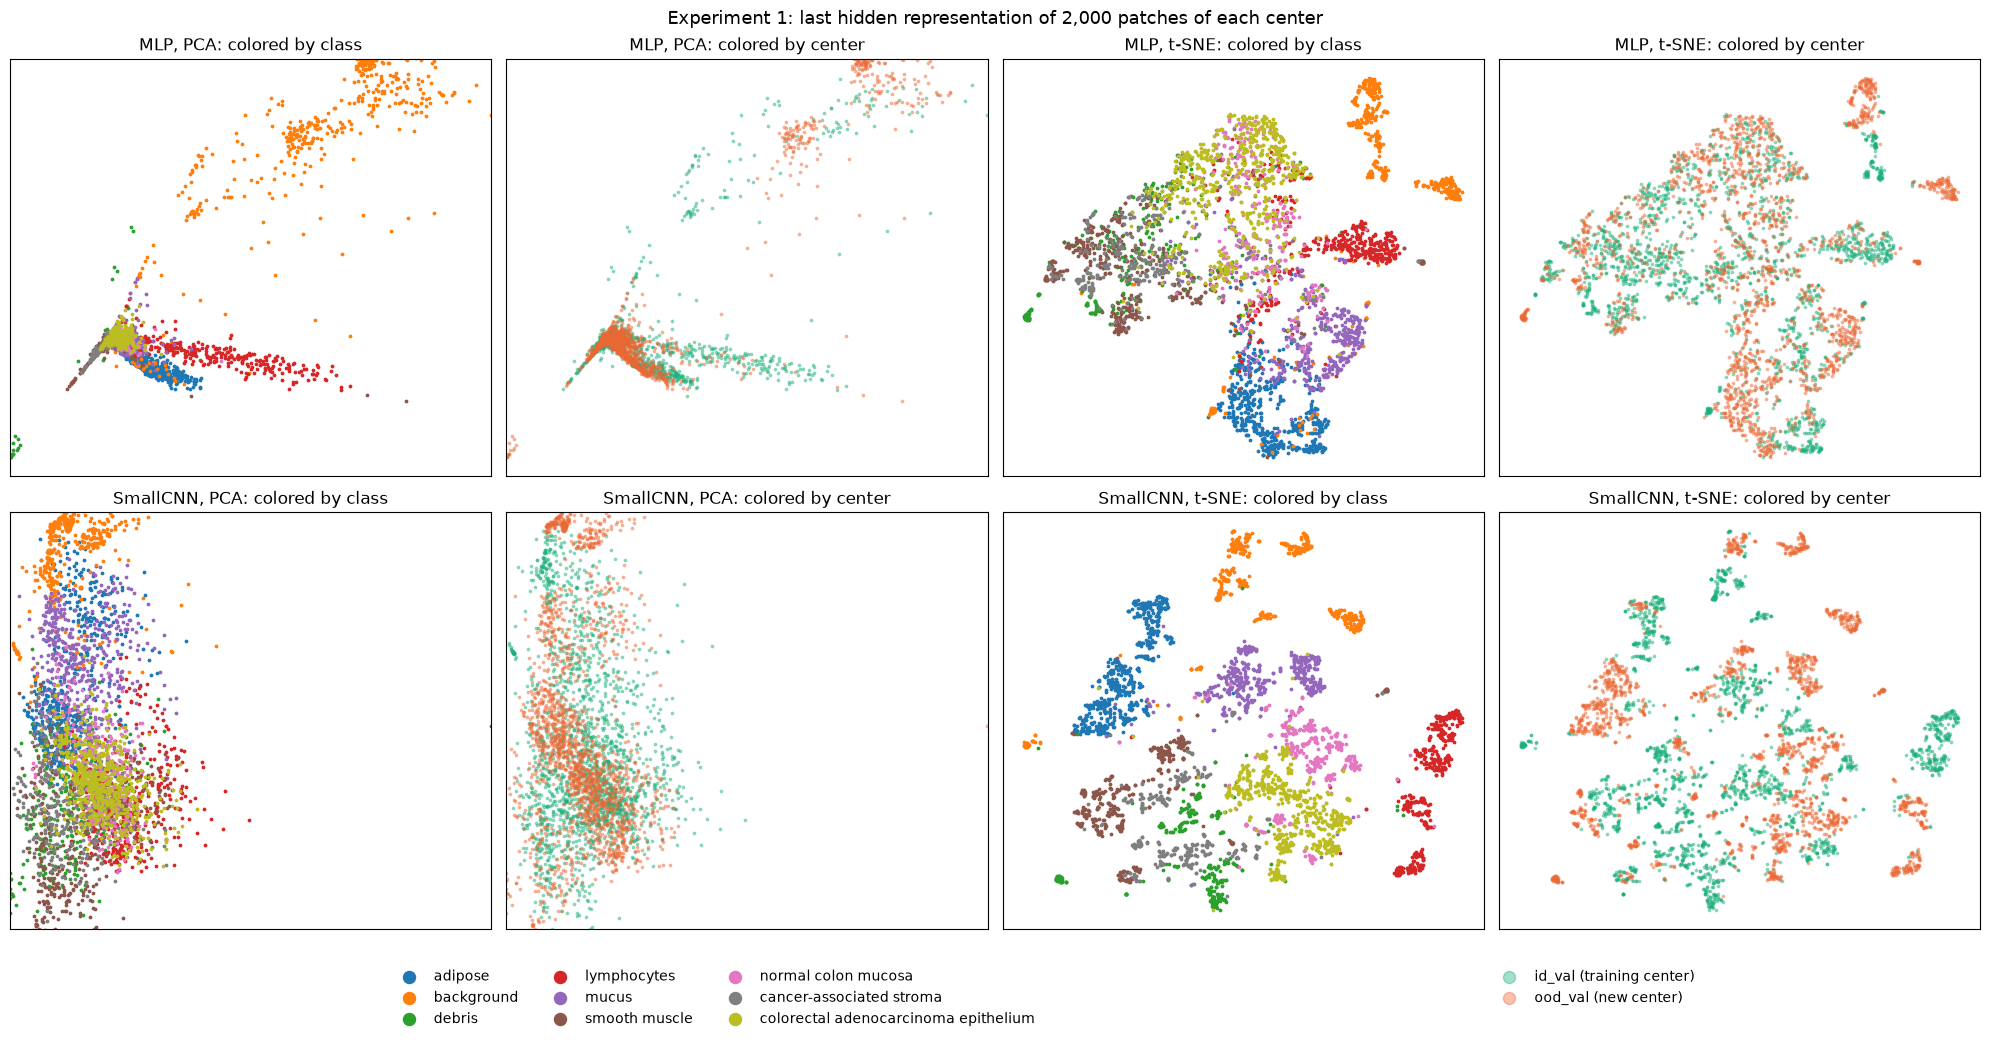

In [26]:
# PLOT: 2D projections (PCA and t-SNE) of the last hidden representation of each model, by class and by center

N_PER_CENTER = 2_000   # patches drawn from each center, so that neither dominates the projection
rng = np.random.default_rng(seed)
proj_idx = {s: rng.choice(len(split_labels[s]), size=N_PER_CENTER, replace=False) for s in ["id_val", "ood_val"]}
proj_X = torch.cat([SPLITS[s][0][proj_idx[s]] for s in proj_idx])
proj_classes = np.concatenate([split_labels[s][proj_idx[s]] for s in proj_idx])
proj_centers = np.repeat(list(proj_idx), N_PER_CENTER)


def last_hidden(model: nn.Module, X: torch.Tensor, batch_size: int = 512) -> np.ndarray:
    # Input of the last linear layer: the representation that the classifier separates with hyperplanes
    model.eval()
    with torch.no_grad():
        return torch.cat([model.net[:-1](rgb(X[i:i + batch_size])).cpu() for i in range(0, len(X), batch_size)]).numpy()


fig, axs = plt.subplots(2, 4, figsize=(20, 10.5))
for r, (name, model) in enumerate(exp1_models.items()):
    h = last_hidden(model, proj_X)
    projections = {"PCA": PCA(2).fit_transform(h), "t-SNE": TSNE(2, init="pca", random_state=seed).fit_transform(h)}
    for p, (method, z) in enumerate(projections.items()):
        ax_class, ax_center = axs[r, 2 * p], axs[r, 2 * p + 1]
        for c in range(len(CLASSES)):
            ax_class.scatter(*z[proj_classes == c].T, s=3, color=plt.cm.tab10(c), label=CLASSES[c])
        for s in proj_idx:
            ax_center.scatter(*z[proj_centers == s].T, s=3, alpha=0.4, color=SPLIT_COLORS[s], label=SPLIT_LABELS[s])
        ax_class.set_title(f"{name}, {method}: colored by class")
        ax_center.set_title(f"{name}, {method}: colored by center")
        if method == "PCA":   # a few distant patches would squeeze all the others into a corner
            lo, hi = np.percentile(z, [0.5, 99.5], axis=0)
            outside = ((z < lo) | (z > hi)).any(axis=1)
            print(f"{name}, PCA: {outside.sum()} patches outside the view, "
                  f"{(outside & (proj_centers == 'ood_val')).sum()} of them from ood_val")
            for ax in (ax_class, ax_center):
                ax.set_xlim(lo[0], hi[0])
                ax.set_ylim(lo[1], hi[1])
for ax in axs.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.36, 0), ncol=3,
           markerscale=5, frameon=False)
fig.legend(*axs[0, 1].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.8, 0.02), ncol=1,
           markerscale=5, frameon=False)
fig.suptitle(f"Experiment 1: last hidden representation of {N_PER_CENTER:,} patches of each center", fontsize=13)
plt.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

### Design justification

> **Question.** (0.5 pt)
>
> Why does comparing an MLP and a SmallCNN, trained from scratch on the same patches, with the same loop and the same
> evaluation splits, isolate the contribution of the convolutional inductive bias? Which factors did you keep fixed,
> and which differences between the two models (besides the inductive bias) could still explain the results?
>
> Which metrics did you use to test the hypothesis, and why do they answer the question?

Treinamos a MLP e a SmallCNN do zero com os mesmos patches RGB, a mesma padronização e sem data augmentations. Nos dois casos, usamos a perda de entropia cruzada, o otimizador Adam com taxa de aprendizado de 0,001, batch de 128 patches, a mesma ordem de apresentação dos patches de treino e 30 épocas. Selecionamos os pesos de cada rede pelo mesmo critério, a maior acurácia balanceada na validação do centro de treino. Dessa forma, a comparação avalia como cada arquitetura aproveita a mesma informação sob as mesmas condições de treinamento.

A principal diferença está na forma como as redes representam a estrutura espacial do tecido. Na MLP, cada posição da imagem achatada tem pesos próprios. Na SmallCNN, um mesmo filtro percorre o patch e pode detectar um padrão local em diferentes posições. As camadas seguintes combinam esses padrões em regiões progressivamente maiores. A comparação avalia essas propriedades em conjunto com outras diferenças entre as arquiteturas. A MLP tem 6.425.609 parâmetros e usa dropout de 0,3, enquanto a SmallCNN tem 94.857 parâmetros e utiliza normalização por batch e pooling. Esses fatores também podem influenciar a otimização e a generalização.

Usamos a acurácia balanceada porque ela dá o mesmo peso ao recall de cada uma das nove classes, cujas proporções diferem entre os centros. O valor em ID mede o desempenho em novos patches do centro de treino, e o valor em OOD mede o desempenho no novo centro. A diferença entre ID e OOD, calculada para cada modelo, responde à segunda parte da hipótese, relacionada a quanto do desempenho obtido no centro de origem se perde com a mudança de centro.

### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of the MLP and of the SmallCNN. Address the following points:
>
> Do the results support or contradict the hypothesis? Refer to specific numbers (ID and OOD balanced accuracy, gap).
>
> Compare the learning curves of the two models. Did the MLP use its extra parameters to fit the training set better?
> What does that say about the relation between the number of parameters and generalization?
>
> Which classes lose the most on the new center, for each model? What do the first-layer weights of the MLP and the
> filters of the CNN look like, and does what each model learned help to explain its behavior on the new center?

A SmallCNN alcançou 98,8% de acurácia balanceada em ID e 88,4% em OOD, enquanto a MLP alcançou 66,5% e 55,0%, respectivamente. A vantagem da SmallCNN no novo centro foi de cerca de 33 pontos percentuais. Além disso, sua queda de ID para OOD foi de 10,4 pontos percentuais, inferior aos 11,5 pontos da MLP. Portanto, os resultados sustentam tanto a previsão de maior acurácia balanceada da SmallCNN nos dois centros quanto a previsão de uma queda menor. Pelo critério definido no enunciado, a hipótese foi sustentada nesta execução.

As curvas mostram que a MLP, apesar de ter cerca de 68 vezes mais parâmetros, também teve mais dificuldade para ajustar os dados de treino. Na primeira época, a SmallCNN já alcançava 86,1% de acurácia de treino, acima dos 79,4% atingidos pela MLP ao fim das 30 épocas. Na época selecionada (28), a SmallCNN tinha 99,0% de acurácia no treino e 98,7% na validação ID. Na MLP, a acurácia de treino continuou subindo enquanto a de validação oscilava próxima de 65%. Nessas condições, a quantidade adicional de parâmetros não se traduziu em melhor ajuste nem em melhor generalização.

A mudança de centro afetou classes diferentes em cada rede. Na MLP, a maior queda ocorreu nos linfócitos, cujo recall passou de 86% em ID para 31% em OOD, seguidos pelo tecido adiposo, de 92% para 72%. A SmallCNN manteve o recall dos linfócitos próximo de 100% no novo centro, mas apresentou quedas acentuadas no estroma associado ao câncer, de 98% para 59%, e no tecido adiposo, de 99% para 74%. A matriz de confusão OOD mostra que os erros dessas duas classes se concentraram no músculo liso: 28% dos patches de estroma e 18% dos patches de tecido adiposo foram classificados como músculo liso.

Nos pesos da primeira camada da MLP, observamos padrões granulados distribuídos por todo o patch, com tonalidades predominantes em algumas unidades. Na SmallCNN, os filtros de 3 × 3 apresentam contrastes de cor e intensidade entre posições vizinhas. Como cada filtro é aplicado em toda a imagem, esses contrastes podem contribuir para reconhecer contornos e texturas onde quer que apareçam. Essa interpretação é compatível com o recall próximo de 100% para linfócitos em OOD e com a separação visual mais clara de várias classes na projeção t-SNE da SmallCNN. Os pesos, por si só, deixam em aberto quanto cada rede depende da cor. Essa dependência pode ser avaliada mais diretamente no experimento de coloração posteriormente.

---

## Experiment 2: Does the Network Know That a Patch Has No "Up"?

A tissue patch has no canonical orientation: rotated by 90°, 180° or 270°, or mirrored, a patch of smooth muscle is
still smooth muscle. These 8 transformations (4 rotations, each with or without a mirror) are **symmetries of the
task**.

Neither architecture has this symmetry built in. An MLP ties each weight to a pixel position, and the filters of a CNN
are oriented: a filter that detects vertical edges does not respond to horizontal ones, so a rotated patch produces
different feature maps. In Lecture 18, a CNN was more tolerant to shifts than an MLP, but it became robust to them
only after **data augmentation** showed it shifted images during training: *convolution gives the network the ability
to detect a pattern anywhere; augmentation teaches it to use that ability*.

The code below provides the 8 symmetries as functions on a batch of images, and an augmentation that applies one of
them, chosen at random, to each training patch.

> **Question:**
>
> Are the models of Experiment 1 invariant to rotations and mirroring of the patch? Does training with these
> symmetries as data augmentation make the MLP and the CNN invariant, and does it reduce the ID–OOD gap?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis. It should predict (i) how the balanced accuracy of the Experiment 1 models changes
> when the evaluation patches are rotated or mirrored, and whether the MLP and the CNN differ, and (ii) the direction
> of the change in OOD balanced accuracy and in the ID–OOD gap when each architecture is trained with the symmetries
> as augmentation. Relate your prediction to the structural properties of each architecture.*

Nossa hipótese é que, nos modelos treinados no Experimento 1, a acurácia balanceada na validação OOD seja menor, em média, nas sete versões rotacionadas ou espelhadas dos patches do que na orientação original. Esperamos uma queda maior na MLP, pois uma rotação ou reflexão desloca estruturas dos dados para posições às quais a rede atribui pesos diferentes. Na SmallCNN, o compartilhamento de filtros permite reconhecer um padrão local em diferentes regiões do patch. Ainda assim, um filtro que responde a uma fibra vertical pode responder de outra forma quando a mesma fibra aparece na horizontal.

Ao treinar cada arquitetura com as oito simetrias do quadrado, esperamos que a diferença entre a maior e a menor acurácia balanceada OOD nas oito orientações diminua em ambos os modelos. Como a classe do tecido é preservada em todas as transformações, o treinamento deve favorecer o reconhecimento das mesmas estruturas em diferentes orientações. Esperamos, porém, que a SmallCNN se beneficie mais. Como seus filtros são compartilhados entre posições, basta que ela aprenda uma vez as versões giradas de cada padrão local para reconhecê-las em todo o patch. A MLP, por atribuir pesos próprios a cada posição, precisa aprender cada estrutura separadamente em cada posição e em cada orientação. Por isso, prevemos que, após o treinamento com as simetrias, a diferença entre a maior e a menor acurácia balanceada OOD nas oito orientações seja menor na SmallCNN do que na MLP.

Nos patches originais do novo centro, prevemos que a MLP supere os 55,0% de acurácia balanceada do Experimento 1 e que sua diferença ID–OOD fique abaixo de 11,5 pontos percentuais. Para a SmallCNN, prevemos acurácia balanceada OOD superior a 88,4% e diferença ID–OOD inferior a 10,4 pontos percentuais. Ao ver cada patch em orientações variadas, a rede tem mais dificuldade para memorizar detalhes específicos dos patches de treino e passa a depender mais da forma, do tamanho e da densidade das estruturas, propriedades que a exploração indicou se manterem entre os centros. Detalhes memorizados do centro de treino ainda ajudam na validação do mesmo centro, mas pouco no novo centro, então o ganho deve ser maior em OOD do que em ID. Na SmallCNN, isso é reforçado pela pouca margem de ganho em ID, onde a acurácia balanceada já é de 98,8%.

A hipótese é contradita se:

- (a) Nos modelos do Experimento 1, a média da acurácia balanceada OOD nas sete versões transformadas não for menor que a da orientação original, ou se a queda da MLP, em pontos percentuais, não for maior que a da SmallCNN

- (b) Com o treinamento com as simetrias, a diferença entre a maior e a menor acurácia balanceada OOD nas oito orientações não diminuir em algum dos modelos, ou não ficar menor na SmallCNN do que na MLP

- (c) A MLP treinada com as simetrias não superar 55,0% de acurácia balanceada OOD ou não ficar com diferença ID–OOD abaixo de 11,5 pontos percentuais

- (d) A SmallCNN treinada com as simetrias não superar 88,4% de acurácia balanceada OOD ou não ficar com diferença ID–OOD abaixo de 10,4 pontos percentuais

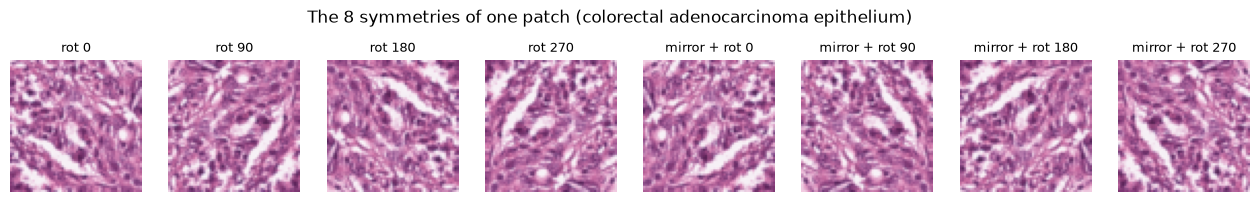

In [27]:
# The 8 symmetries of the square, as functions on a batch of images with shape (batch, channels, height, width).
SYMMETRIES = {
    f"{'mirror + ' if mirror else ''}rot {90 * k}": (
        lambda x, k=k, mirror=mirror: torch.rot90(x.flip(3) if mirror else x, k, dims=(2, 3))
    )
    for mirror in (False, True)
    for k in range(4)
}


def random_symmetry(x: torch.Tensor) -> torch.Tensor:
    # Augmentation: applies one of the 8 symmetries, chosen at random for each image, to a batch (N, C, H, W).
    mirror = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(mirror[:, None, None, None], x.flip(3), x)
    k = torch.randint(4, (len(x),), device=x.device)
    out = x.clone()
    for r in range(1, 4):
        out[k == r] = torch.rot90(x[k == r], r, dims=(2, 3))
    return out


# One OOD validation patch under the 8 symmetries
X, y = SPLITS["ood_val"]
patch = X[:1].float().div(255)
fig, axs = plt.subplots(1, len(SYMMETRIES), figsize=(16, 2.4))
for ax, (name, fn) in zip(axs, SYMMETRIES.items()):
    ax.imshow(fn(patch)[0].permute(1, 2, 0).numpy())
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.suptitle(f"The 8 symmetries of one patch ({CLASSES[y[0].item()]})", fontsize=12)
plt.show()

In [28]:
# Part (i): the models of Experiment 1, without retraining, evaluated on the OOD validation patches transformed by each
# of the 8 symmetries. Besides the balanced accuracy, the agreement (fraction of the patches whose predicted class is
# the same as on the original patch) measures the invariance directly: an invariant model has agreement 1.0.


def symmetry_metrics(model: nn.Module, split: str = "ood_val") -> pd.DataFrame:
    # Balanced accuracy and agreement with the prediction on the original patch, under each of the 8 symmetries
    loader = make_loader(split)
    original, labels = predict(model, loader, rgb)
    rows = {}
    for name, fn in SYMMETRIES.items():
        preds, _ = predict(model, loader, rgb, input_fn=fn)
        rows[name] = {"bal_acc": balanced_accuracy_score(labels, preds), "agreement": np.mean(preds == original)}
    return pd.DataFrame(rows).T


sym_metrics = {"MLP (Exp. 1)": symmetry_metrics(mlp), "SmallCNN (Exp. 1)": symmetry_metrics(cnn)}
display(pd.concat(sym_metrics, axis=1).round(3))

MLP (Exp. 1)           SmallCNN (Exp. 1)          
                      bal_acc agreement           bal_acc agreement
rot 0                   0.550     1.000             0.884     1.000
rot 90                  0.546     0.717             0.897     0.923
rot 180                 0.556     0.726             0.877     0.947
rot 270                 0.558     0.725             0.898     0.922
mirror + rot 0          0.546     0.731             0.894     0.936
mirror + rot 90         0.551     0.722             0.880     0.934
mirror + rot 180        0.549     0.730             0.896     0.934
mirror + rot 270        0.554     0.733             0.889     0.938

In [29]:
# Part (ii): a new MLP and a new SmallCNN, trained from scratch as in Experiment 1 (same initialization seed, optimizer,
# learning rate, number of epochs and early stopping on the ID validation), with a random symmetry applied to each
# training patch. As in Experiment 1, each training gets its own loader, with the same order of the training patches.

torch.manual_seed(seed)
mlp_sym = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256], dropout=dropout).to(DEVICE)
mlp_sym_optimizer = optim.Adam(mlp_sym.parameters(), lr=learning_rate)

mlp_sym_history = fit(mlp_sym, make_loader("train", batch_size=128, shuffle=True), id_val_loader, mlp_sym_optimizer,
                      n_epochs, rgb, augment=random_symmetry)
report("MLP + symmetries (Exp. 2)", mlp_sym, rgb, mlp_sym_history)
sym_metrics["MLP + symmetries (Exp. 2)"] = symmetry_metrics(mlp_sym)

epoch  1/30 | train loss 1.2900 | train acc 0.499 | val acc 0.602 | val bal. acc 0.592  *


epoch  2/30 | train loss 1.1116 | train acc 0.571 | val acc 0.594 | val bal. acc 0.581


epoch  3/30 | train loss 1.0757 | train acc 0.587 | val acc 0.623 | val bal. acc 0.612  *


epoch  4/30 | train loss 1.0464 | train acc 0.599 | val acc 0.617 | val bal. acc 0.625  *


epoch  5/30 | train loss 1.0360 | train acc 0.604 | val acc 0.638 | val bal. acc 0.634  *


epoch  6/30 | train loss 1.0215 | train acc 0.611 | val acc 0.643 | val bal. acc 0.620


... (20 outputs left out)

epoch 27/30 | train loss 0.9410 | train acc 0.648 | val acc 0.681 | val bal. acc 0.676  *


epoch 28/30 | train loss 0.9535 | train acc 0.644 | val acc 0.675 | val bal. acc 0.666


epoch 29/30 | train loss 0.9476 | train acc 0.645 | val acc 0.689 | val bal. acc 0.684  *


epoch 30/30 | train loss 0.9452 | train acc 0.648 | val acc 0.672 | val bal. acc 0.664
best epoch: 29 (val bal. acc 0.684) | training time: 140 s
MLP + symmetries (Exp. 2): ID bal. acc 0.684 | OOD bal. acc 0.566 | gap +0.118 | ID acc 0.689 | OOD acc 0.636


In [30]:
torch.manual_seed(seed)
cnn_sym = SmallCNN().to(DEVICE)
cnn_sym_optimizer = optim.Adam(cnn_sym.parameters(), lr=learning_rate)

cnn_sym_history = fit(cnn_sym, make_loader("train", batch_size=128, shuffle=True), id_val_loader, cnn_sym_optimizer,
                      n_epochs, rgb, augment=random_symmetry)
report("SmallCNN + symmetries (Exp. 2)", cnn_sym, rgb, cnn_sym_history)
sym_metrics["SmallCNN + symmetries (Exp. 2)"] = symmetry_metrics(cnn_sym)

epoch  1/30 | train loss 0.4501 | train acc 0.855 | val acc 0.753 | val bal. acc 0.759  *


epoch  2/30 | train loss 0.1999 | train acc 0.936 | val acc 0.876 | val bal. acc 0.873  *


epoch  3/30 | train loss 0.1533 | train acc 0.950 | val acc 0.935 | val bal. acc 0.932  *


epoch  4/30 | train loss 0.1290 | train acc 0.958 | val acc 0.944 | val bal. acc 0.945  *


epoch  5/30 | train loss 0.1155 | train acc 0.963 | val acc 0.962 | val bal. acc 0.963  *


epoch  6/30 | train loss 0.1015 | train acc 0.967 | val acc 0.924 | val bal. acc 0.923


... (21 outputs left out)

epoch 28/30 | train loss 0.0380 | train acc 0.987 | val acc 0.983 | val bal. acc 0.983


epoch 29/30 | train loss 0.0361 | train acc 0.988 | val acc 0.987 | val bal. acc 0.986


epoch 30/30 | train loss 0.0354 | train acc 0.988 | val acc 0.983 | val bal. acc 0.984
best epoch: 24 (val bal. acc 0.989) | training time: 402 s


SmallCNN + symmetries (Exp. 2): ID bal. acc 0.989 | OOD bal. acc 0.894 | gap +0.095 | ID acc 0.988 | OOD acc 0.921


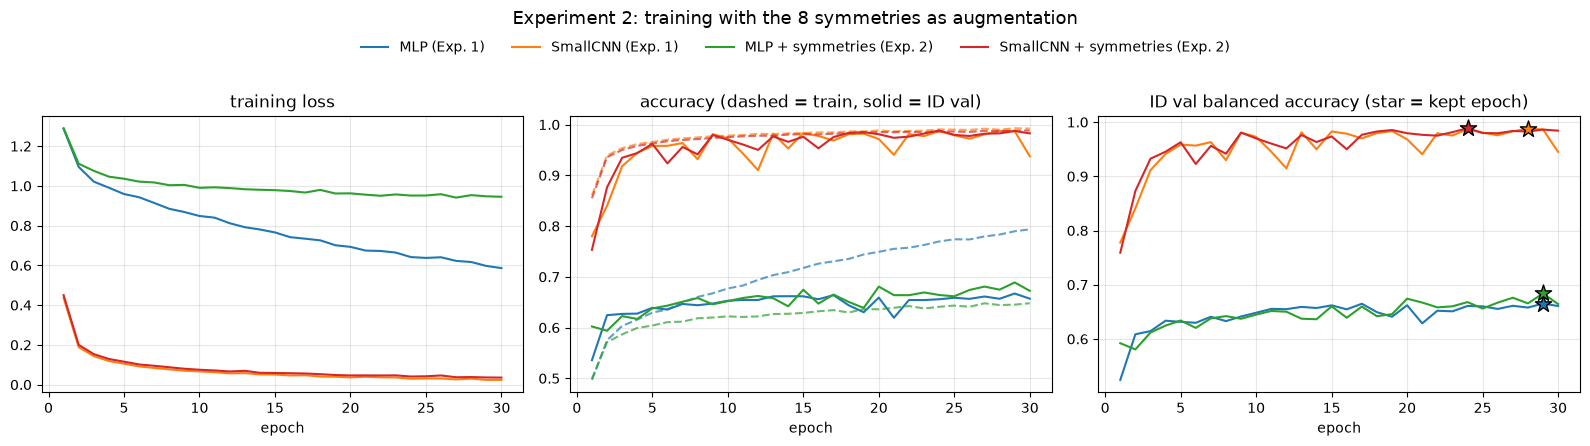

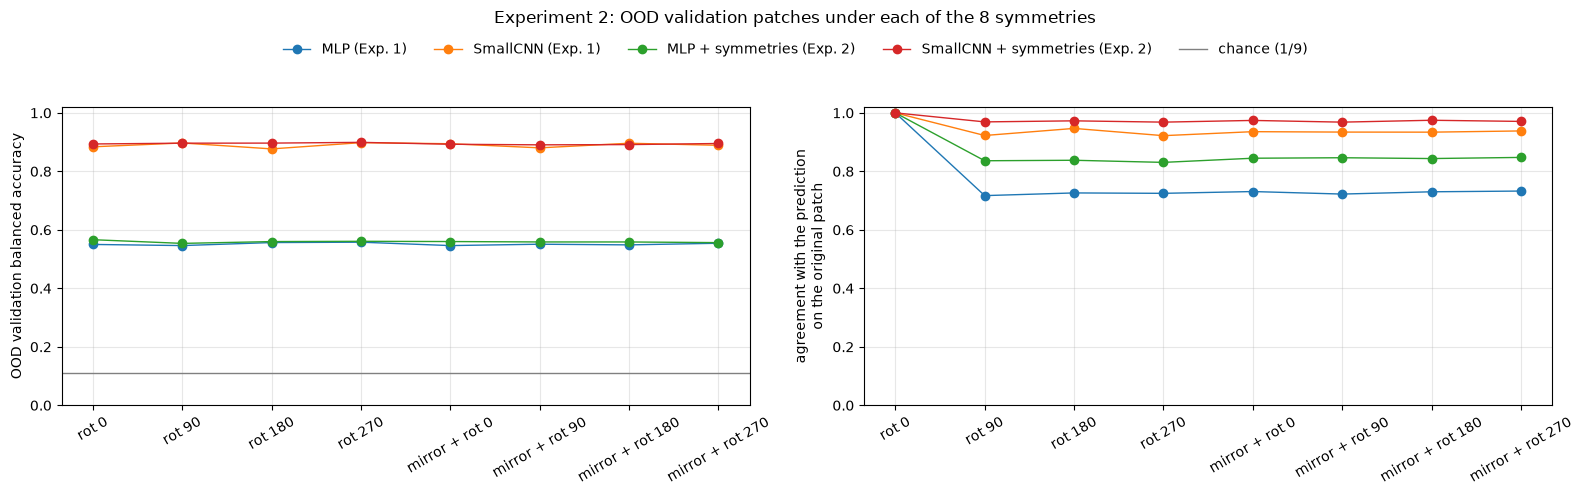

,ID bal. acc,OOD bal. acc,gap,"OOD bal. acc, worst symmetry","agreement, mean of the 7 symmetries"
MLP (Exp. 1),0.665,0.550,0.115,0.546,0.726
SmallCNN (Exp. 1),0.988,0.884,0.104,0.877,0.933
MLP + symmetries (Exp. 2),0.684,0.566,0.118,0.554,0.841
SmallCNN + symmetries (Exp. 2),0.989,0.894,0.095,0.891,0.971


In [31]:
# PLOT: learning curves of the four models, and their balanced accuracy and agreement under each symmetry

exp2_histories = {
    "MLP (Exp. 1)": mlp_history,
    "SmallCNN (Exp. 1)": cnn_history,
    "MLP + symmetries (Exp. 2)": mlp_sym_history,
    "SmallCNN + symmetries (Exp. 2)": cnn_sym_history,
}
plot_histories(exp2_histories, "Experiment 2: training with the 8 symmetries as augmentation")

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for name, color in zip(exp2_histories, plt.cm.tab10.colors):           # same colors as the learning curves
    for ax, metric in zip(axs, ["bal_acc", "agreement"]):
        ax.plot(sym_metrics[name].index, sym_metrics[name][metric], "o-", linewidth=1, color=color, label=name)
axs[0].axhline(1 / len(CLASSES), color="gray", linewidth=1, label="chance (1/9)")
axs[0].set_ylabel("OOD validation balanced accuracy")
axs[1].set_ylabel("agreement with the prediction\non the original patch")
for ax in axs:
    ax.set_ylim(0, 1.02)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=5, frameon=False)
fig.suptitle("Experiment 2: OOD validation patches under each of the 8 symmetries", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

display(pd.DataFrame({name: {
    "ID bal. acc": RESULTS[name]["id_bal_acc"],
    "OOD bal. acc": RESULTS[name]["ood_bal_acc"],
    "gap": RESULTS[name]["gap_bal_acc"],
    "OOD bal. acc, worst symmetry": sym_metrics[name]["bal_acc"].min(),
    "agreement, mean of the 7 symmetries": sym_metrics[name]["agreement"].drop("rot 0").mean(),
} for name in exp2_histories}).T.round(3))

### Design justification

> **Question.** (0.5 pt)
>
> Explain your experiment configuration: what remained the same as in Experiment 1 and what changed. Why does
> evaluating a model on transformed copies of the same patches measure its invariance? Why is the augmentation the only
> difference between the two trainings of each architecture? How does your experiment answer the question?

Primeiro, avaliamos a MLP e a SmallCNN do Experimento 1, sem retreinamento, nas oito orientações dos mesmos patches de validação OOD. Para cada patch, usamos a imagem original e as sete versões obtidas por rotação ou espelhamento e fizemos a comparação de forma pareada. Se a classe prevista muda quando giramos um patch, identificamos diretamente uma sensibilidade do modelo à orientação. Por isso, além da acurácia balanceada, medimos a proporção de patches que mantêm a mesma predição da imagem original. As duas métricas se complementam, pois a acurácia pode permanecer estável mesmo quando o modelo passa a acertar alguns patches e a errar outros, o que não nos permitiria isolar o efeito das transformações.

Em seguida, treinamos uma nova MLP e uma nova SmallCNN do zero, mantendo as mesmas configurações anteriores para treinamento. A única mudança nessa etapa foi sortear, a cada apresentação de um patch, uma das oito simetrias do quadrado. Assim, o Experimento 1 serve de referência para avaliar o efeito do aumento de dados na sua própria arquitetura.

Para testar a previsão de que a MLP seria inicialmente mais sensível à orientação, comparamos, em cada modelo do Experimento 1, a acurácia balanceada OOD na imagem original com a média nas sete versões transformadas. Para avaliar o efeito do treino com simetrias, comparamos a diferença entre a maior e a menor acurácia nas oito orientações, antes e depois do aumento de dados. Essa medida permite verificar tanto se a variação diminuiu em cada rede quanto se a SmallCNN terminou com uma variação menor que a MLP. Por fim, avaliamos os quatro modelos nos patches originais de ID e OOD. A acurácia balanceada OOD mostra se houve ganho no novo centro, enquanto a diferença ID–OOD indica se esse ganho foi maior do que o obtido no centro de treino.

### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of the symmetry experiment. Address the following points:
>
> Were the models of Experiment 1 invariant to the symmetries? Did the MLP and the CNN behave differently? Refer to
> specific numbers.
>
> Did augmentation make each architecture invariant? Did it help the CNN and the MLP equally? Relate your answer to the
> sentence from Lecture 18 quoted above.
>
> Did augmentation change the ID–OOD gap? Augmentation also acts as a regularizer, because the model rarely sees
> exactly the same image twice. Can you attribute the change in OOD performance to the invariance itself, rather than
> to less overfitting?

Os modelos do Experimento 1 apresentaram sensibilidades diferentes à orientação dos patches. Nas sete versões rotacionadas ou espelhadas, a MLP manteve a predição da imagem original em 72,6% dos casos, enquanto a SmallCNN alcançou 93,3% de concordância, indicando que a MLP mudou de predição com mais frequência, conforme esperado. Entretanto, a queda prevista na acurácia balanceada OOD não foi observada, pois a média das sete transformações ficou em 55,1% na MLP, praticamente igual aos 55,0% da orientação original, enquanto a SmallCNN atingiu 89,0%, superando os 88,4% originais. O comportamento da MLP evidencia a importância de considerar as duas métricas, uma vez que as transformações alteraram mais de um quarto de suas predições, mas os acertos ganhos em alguns patches compensaram os perdidos em outros.

O treinamento com simetrias aumentou a concordância média de 72,6% para 84,1% na MLP e de 93,3% para 97,1% na SmallCNN, de modo que a MLP apresentou o maior ganho nessa métrica, de 11,5 pontos percentuais, enquanto a SmallCNN terminou com as predições mais estáveis. Em relação à amplitude da acurácia balanceada nas oito orientações, o gráfico mostra uma redução clara na SmallCNN, de 2,1 para 0,9 ponto percentual, ao passo que, na MLP, a amplitude permaneceu próxima de 1,2 ponto percentual observados antes do aumento de dados. Dessa forma, os resultados sustentam a previsão de uma amplitude final menor na SmallCNN, mas não evidenciam uma redução clara em ambas as redes. Esse resultado se relaciona com a frase da Aula 18 citada no enunciado: a convolução dá à rede a capacidade de detectar um padrão em qualquer posição, e a augmentation a ensina a usar essa capacidade. A SmallCNN, que já possuía essa capacidade, partiu de 93,3% de concordância e chegou a 97,1%, ficando próxima da invariância, embora sem alcançá-la. A MLP teve o maior ganho absoluto, mas partiu de um patamar mais baixo e, mesmo após o treinamento com simetrias, ainda alterou cerca de 16% de suas predições. Sem pesos compartilhados entre posições, a augmentation precisa ensiná-la a reconhecer cada estrutura separadamente em cada posição e orientação. Assim, a augmentation ajudou as duas redes, mas não igualmente: nenhuma se tornou invariante, e apenas a SmallCNN se aproximou disso.

Nos patches originais do novo centro, ambas as arquiteturas apresentaram melhora, com a acurácia balanceada OOD da MLP passando de 55,0% para 56,6%. Entretanto, como o ganho em ID foi ligeiramente maior, de 66,5% para 68,4%, a diferença ID–OOD aumentou de 11,5 para 11,8 pontos percentuais, contrariando a previsão de redução. Na SmallCNN, por outro lado, a acurácia balanceada OOD subiu de 88,4% para 89,4%, enquanto a ID passou de 98,8% para 98,9%, reduzindo a diferença ID–OOD de 10,4 para 9,5 pontos percentuais. Assim, embora as duas redes tenham apresentado ganhos em OOD, apenas a SmallCNN também alcançou a redução prevista na diferença entre os centros.

O treinamento com simetrias produz dois efeitos ao mesmo tempo: aumenta a invariância à orientação, como mostra a concordância, e reduz o sobreajuste, pois a rede raramente vê duas vezes a mesma imagem. As curvas de aprendizado ajudam a separá-los em parte. Na MLP, a augmentation atuou claramente como regularização: no Experimento 1, a acurácia de treino, medida durante o treino, terminou em 79,4%, contra 65,7% na validação ID, enquanto com as simetrias terminou em 64,8%, abaixo dos 67,2% da validação. Ainda assim, as acurácias ID e OOD da MLP subiram em proporções semelhantes, 1,9 e 1,6 pontos percentuais, e sua diferença ID–OOD não diminuiu. Na SmallCNN, quase não havia sobreajuste a remover: na época selecionada, a acurácia era de 99,0% no treino e 98,7% na validação ID no Experimento 1, e de 98,6% e 98,8% com as simetrias. A redução do sobreajuste, portanto, explica mal o ganho em OOD da SmallCNN, que é mais compatível com o aumento da invariância. Essa atribuição, porém, é limitada: com uma única seed, as variações da SmallCNN, de 1,0 ponto percentual em OOD e 0,9 ponto na diferença ID–OOD, são menores que a variação de 3,5 pontos causada apenas pela mudança na ordem dos mini-batches no Experimento 1, o que será avaliado com mais seeds no Experimento 4.

Em conjunto, os resultados contradizem a hipótese pelos critérios definidos. A previsão (a) falhou nos dois modelos, pois nenhuma rede perdeu acurácia balanceada nas versões transformadas. A previsão (b) se cumpriu apenas em parte: a amplitude da SmallCNN terminou menor que a da MLP, mas a da MLP não diminuiu. A previsão (c) falhou na diferença ID–OOD da MLP, embora sua acurácia OOD tenha aumentado. Apenas a previsão (d), de maior acurácia OOD e menor diferença ID–OOD na SmallCNN, foi sustentada, e com variações pequenas diante do ruído entre execuções. O treinamento com simetrias tornou as duas redes mais estáveis à orientação, sobretudo a SmallCNN, mas não mostrou um efeito claro sobre a diferença entre os centros.

---

## Experiment 3: Is the Stain Color a Shortcut?

Each center has its own staining protocol and scanner, so the colors of a patch partly encode **where** it was
acquired. A network trained on a single center may learn to recognize a tissue by the exact shades it has in that
center, a **shortcut** that fits the training data but does not transfer to a center whose stains look different,
even if the morphology of the tissue is the same.

There are two opposite ways to prevent a network from relying on the exact colors:
- **remove them**: train and evaluate on grayscale patches. The network cannot use color at all, but it also loses
  the difference between the purple of hematoxylin (nuclei) and the pink of eosin (cytoplasm, fibers), which a
  pathologist uses;
- **randomize them**: keep the colors, but change the amount of each stain at random in every training patch
  (**stain augmentation**, Tellez et al., 2019), so that no exact shade is reliably associated with a class.

`stain_jitter` below converts each RGB patch into the concentrations of hematoxylin, eosin and DAB (the color
deconvolution of `skimage.color.rgb2hed`), multiplies each concentration by a random factor in [1 − `scale`,
1 + `scale`], adds a random shift in [−`shift`, `shift`], and converts back to RGB. Every patch gets its own factors.

> **Question:**
>
> Does the CNN rely on the exact stain colors of the training center? Which strategy reduces the ID–OOD gap more:
> removing color (grayscale) or randomizing the stains during training (stain augmentation)?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis. It should predict the direction of the change in ID balanced accuracy, OOD
> balanced accuracy and ID–OOD gap for each of the two strategies, relative to the CNN of the previous experiments, and
> which strategy is better. Consider both what color reveals about the center and what it reveals about the tissue,
> and relate your prediction to the Data Exploration.*

*YOUR ANSWER HERE*

In [ ]:
# (a) Grayscale: the same gray image in the 3 channels (so the architecture does not change), standardized with
#     statistics of the grayscale training split. Used for training AND evaluation.
def grayscale(x: torch.Tensor) -> torch.Tensor:
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    return gray.expand(-1, 3, -1, -1)


gray = Preprocess(color_fn=grayscale)


# (b) Stain augmentation, for the TRAINING split only (the model is evaluated with `rgb`).
RGB_FROM_HED = torch.tensor([[0.65, 0.70, 0.29],    # hematoxylin
                             [0.07, 0.99, 0.11],    # eosin
                             [0.27, 0.57, 0.78]])   # DAB      (the matrix of skimage.color.rgb2hed)
HED_FROM_RGB = torch.linalg.inv(RGB_FROM_HED)


def stain_jitter(x: torch.Tensor, scale: float = 0.2, shift: float = 0.05) -> torch.Tensor:
    # Random change of the amount of each stain, with its own factors for each image of a batch (N, 3, H, W) in [0, 1].
    optical_density = -torch.log(x.clamp(min=1e-6)).permute(0, 2, 3, 1)           # (N, H, W, 3)
    stains = optical_density @ HED_FROM_RGB.to(x.device)                         # concentrations of H, E and DAB
    factors = 1 + scale * (2 * torch.rand(len(x), 1, 1, 3, device=x.device) - 1)
    shifts = shift * (2 * torch.rand(len(x), 1, 1, 3, device=x.device) - 1)
    stains = stains * factors + shifts
    return torch.exp(-(stains @ RGB_FROM_HED.to(x.device))).clamp(0, 1).permute(0, 3, 1, 2)


# Choose the strength of the augmentation and justify it: the default values are only a starting point.
# Example of use: fit(..., preprocess=rgb, augment=stain_jitter). If you start from Experiment 2, combine both:
# augment=lambda x: random_symmetry(stain_jitter(x)).

In [ ]:
# The same training patches: original, grayscale and four draws of stain augmentation
X, y = SPLITS["train"]
patches = X[:6].float().div(255)
torch.manual_seed(seed)
rows = {"original": patches, "grayscale": grayscale(patches)}
rows.update({f"stain jitter {k + 1}": stain_jitter(patches) for k in range(4)})

fig, axs = plt.subplots(len(rows), len(patches), figsize=(1.8 * len(patches), 1.9 * len(rows)), constrained_layout=True)
for i, (name, batch) in enumerate(rows.items()):
    for j in range(len(patches)):
        axs[i, j].imshow(batch[j].permute(1, 2, 0).numpy())
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        if i == 0:
            axs[i, j].set_title(CLASSES[y[j].item()], fontsize=7)
    axs[i, 0].set_ylabel(name, fontsize=9)
plt.show()

In [ ]:
# Your code here: start from the SmallCNN configuration of Experiment 1 or 2 (state which one) and change ONLY the
# color processing, so that the effect of color is isolated. Train the grayscale CNN and the stain-augmented CNN,
# evaluate them with report() (gray for the grayscale CNN, rgb for the stain-augmented one) and analyze.

### Design justification

> **Question.** (0.5 pt)
>
> Explain your experiment configuration: which CNN you started from, what remained the same and what changed. Why do
> the two strategies test whether the CNN relies on the exact colors, and what does each of them assume about the data?
> How does your experiment answer the question?

*YOUR ANSWER HERE*

### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of removing and of randomizing the colors. Address the following points:
>
> Does each strategy improve or degrade the ID metrics? And the OOD metrics? Was this consistent with your hypothesis?
>
> Which classes gain or lose the most with each strategy? Can you attribute the results uniquely to color? Think
> about what else grayscale and stain augmentation change.
>
> How do the results connect with the Data Exploration you conducted?

*YOUR ANSWER HERE*

---

## Experiment 4: Is the Gap Real, and Where Does It Come From?

Experiments 1-3 compared models trained with a single seed, and measured a single number for the gap. Two questions
remain before choosing a final model.

**Is a difference between two models larger than the noise of training?** The seed changes the initialization, the
order of the mini-batches and the augmentations. On distribution-shift benchmarks, the OOD performance of the same
configuration can change a lot from one seed to another: on Camelyon17, another histopathology task, the WILDS
benchmark reports 70.3 ± 6.4% OOD accuracy over 10 seeds. A difference between two models smaller than this
variation is not evidence of anything.

**Where does the gap come from?** The new center differs in the appearance of the patches (*covariate shift*), but
it may also have different proportions of the 9 classes (*label shift*). The two effects can be separated. Let
$r_{\text{ID}}(c)$ be the recall of class $c$ on `id_val`, and $\pi_{\text{OOD}}(c)$ the proportion of class $c$ in
`ood_val`. If only the proportions changed, and each class were recognized as well as in the ID validation, the OOD
accuracy would be

$$
\text{acc}_{\text{prop}} = \sum_{c=0}^{8} \pi_{\text{OOD}}(c)\, r_{\text{ID}}(c),
$$

and the accuracy gap splits into two terms:

$$
\underbrace{\text{acc}_{\text{ID}} - \text{acc}_{\text{OOD}}}_{\text{total gap}}
= \underbrace{\text{acc}_{\text{ID}} - \text{acc}_{\text{prop}}}_{\text{change of proportions}}
+ \underbrace{\text{acc}_{\text{prop}} - \text{acc}_{\text{OOD}}}_{\text{change of appearance}} .
$$

Steps:
1. **Seeds.** Retrain the MLP and the SmallCNN of Experiment 1, and the best variant of Experiment 2 and of
   Experiment 3 (chosen by ID validation balanced accuracy), with **at least 3 seeds** each (the seed used before
   counts as one). Report the mean and the standard deviation of the ID balanced accuracy, of the OOD balanced
   accuracy and of the gap.
2. **Decomposition.** Implement `gap_decomposition` and apply it to the SmallCNN of Experiment 1 and to your best
   variant.
3. **Final model.** Choose a final model using **only the ID validation**: one of the configurations above, or a new
   one that combines what worked (architecture, augmentations, the regularization tools of Lecture 18 such as dropout
   and weight decay, more epochs; you may also fine-tune a pretrained ResNet-18 from `torchvision.models`). Report its
   number of parameters and its training time, and evaluate it **once** on `ood_test`.

> **Question:**
>
> Are the differences between the models of Experiments 1-3 larger than the variation caused by the random seed? And
> is the ID–OOD gap of the CNN caused mainly by the change of class proportions or by the change of appearance of the
> patches?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis that answers both parts of the question: which of the comparisons of Experiments 1-3
> you expect to survive the variation between seeds, and which of the two terms of the decomposition you expect to
> dominate the gap of the CNN. Base the second prediction on your Data Exploration.*

*YOUR ANSWER HERE*

In [ ]:
def run_seeds(build_model, build_optimizer, n_epochs: int, preprocess: Preprocess, augment=None,
              seeds=(42, 43, 44)) -> pd.DataFrame:
    # Trains the same configuration with several seeds and returns one row of metrics per seed.
    rows = []
    for s in seeds:
        torch.manual_seed(s)
        model = build_model().to(DEVICE)
        train = make_loader("train", batch_size=128, shuffle=True, shuffle_seed=s)
        fit(model, train, make_loader("id_val"), build_optimizer(model), n_epochs, preprocess, augment, verbose=False)
        id_m = evaluate(model, make_loader("id_val"), preprocess)
        ood_m = evaluate(model, make_loader("ood_val"), preprocess)
        rows.append({"seed": s, "id_bal_acc": id_m["bal_acc"], "ood_bal_acc": ood_m["bal_acc"],
                     "gap_bal_acc": id_m["bal_acc"] - ood_m["bal_acc"]})
        print(f"seed {s}: ID bal. acc {id_m['bal_acc']:.3f} | OOD bal. acc {ood_m['bal_acc']:.3f}")
    return pd.DataFrame(rows)


# Example (adapt to your configurations):
# seed_results = {
#     "SmallCNN (Exp. 1)": run_seeds(lambda: SmallCNN(), lambda m: optim.Adam(m.parameters(), lr=learning_rate),
#                                    n_epochs, rgb),
#     ...
# }
# seed_summary = pd.DataFrame({name: df.drop(columns="seed").agg(["mean", "std"]).unstack()
#                              for name, df in seed_results.items()}).T
# display(seed_summary)

In [ ]:
def gap_decomposition(model: nn.Module, preprocess: Preprocess) -> dict[str, float]:
    # Splits the ID-OOD accuracy gap into a change of class proportions and a change of appearance.
    # TODO: with predict() on id_val and on ood_val, compute
    #   - acc_id and acc_ood, the accuracies on id_val and on ood_val;
    #   - recall_id[c], the recall of each class on id_val, and prop_ood[c], the proportion of each class in ood_val;
    #   - acc_prop = sum over c of prop_ood[c] * recall_id[c];
    # and return the total gap and its two terms.
    return {"total_gap": ..., "proportions": ..., "appearance": ...}

In [ ]:
# Your code here: seeds, decomposition, and the training of your final model (use report() to add it to RESULTS).

final_name = ...   # the name of your final model in RESULTS

In [ ]:
# OOD test: run this cell only once, after all decisions are made. The SmallCNN of Experiment 1 is evaluated as a
# reference.
for name in dict.fromkeys([final_name, "SmallCNN (Exp. 1)"]):
    model, preprocess = MODELS[name]
    test = evaluate(model, make_loader("ood_test"), preprocess)
    RESULTS[name].update(test_acc=test["acc"], test_bal_acc=test["bal_acc"])
    print(f"{name}: OOD test acc {test['acc']:.3f} | OOD test bal. acc {test['bal_acc']:.3f}")

### Discussion: seeds and decomposition

> **Question.** (1.0 pt)
>
> Do the results support or contradict your hypothesis? Refer to specific numbers.
>
> Which conclusions of Experiments 1-3 survive the variation between seeds, and which should be revised?
>
> How is the gap of the CNN divided between the change of proportions and the change of appearance? What does the
> decomposition say about the difference between the accuracy and the balanced accuracy, and about which kind of
> intervention (architecture, augmentation, color) can reduce each term?

*YOUR ANSWER HERE*

### Discussion: final model

> **Question.** (1.0 pt)
>
> What is your final model, how many parameters does it have, and how long did it take to train? Compare it with the
> previous models and draw a link with the results.
>
> How does its performance on `ood_test` compare with its performance on `ood_val`, and with the SmallCNN of
> Experiment 1? Did the gap shrink?
>
> If your results are positive, can you attribute with certainty which change contributed most? Conversely, if they
> are negative, provide an alternative explanation that is consistent with the failure.

*YOUR ANSWER HERE*

---

## Summary

Complete the table below with the results of your experiments. The seed column comes from Experiment 4, and the
test columns are filled in only for the two models evaluated on `ood_test`.

| Model | Parameters | Training time (s) | ID val bal. acc | OOD val bal. acc | Gap (bal. acc) | OOD val bal. acc over seeds (mean ± std) | OOD test bal. acc | OOD test acc |
|---|---|---|---|---|---|---|---|---|
| MLP (Exp. 1) | | | | | | | – | – |
| SmallCNN (Exp. 1) | | | | | | | | |
| MLP + symmetries (Exp. 2) | | | | | | | – | – |
| SmallCNN + symmetries (Exp. 2) | | | | | | | – | – |
| SmallCNN, grayscale (Exp. 3) | | | | | | | – | – |
| SmallCNN + stain augmentation (Exp. 3) | | | | | | | – | – |
| Final model (Exp. 4): *name* | | | | | | | | |

*Gap = ID val balanced accuracy − OOD val balanced accuracy. Leave the seed column empty for the configurations you
did not retrain.*

---

## References

- J. N. Kather et al. *Predicting survival from colorectal cancer histology slides using deep learning: A
  retrospective multicenter study.* PLOS Medicine, 2019.
- J. Yang et al. *MedMNIST v2 - A large-scale lightweight benchmark for 2D and 3D biomedical image classification.*
  Scientific Data, 2023.
- D. Tellez et al. *Quantifying the effects of data augmentation and stain color normalization in convolutional
  neural networks for computational pathology.* Medical Image Analysis, 2019.
- P. W. Koh et al. *WILDS: A Benchmark of in-the-Wild Distribution Shifts.* ICML, 2021.

---
### Declaração de Uso de IA generativa

Conforme a diretriz 4, declaramos que utilizamos o modelo Claude Opus 5.5 (Anthropic), por meio da extensão Claude Code para o VS Code, como assistente de implementação durante a realização desta tarefa.

Os prompts empregados foram, em sua maioria, dos seguintes tipos:

- Correção de bugs e de problemas de exibição;
- Melhoria da legibilidade dos gráficos e da organização do código;
- Verificação de consistência entre os números da tabela do Summary e as saídas do notebook;
- Correção gramatical pontual nas respostas.

As respostas às questões foram redigidas pelos integrantes do grupo, e todo o código gerado foi revisado por eles antes de ser incorporado.

---

## Assignment Submission

This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.

Before submitting, verify that:
- The notebook runs end-to-end without errors (use **Run All** after restarting the kernel).
- All plots are rendered in the output.
- All written sections (Hypothesis, Design, Discussion) are filled in.
- The Summary table is completed.
- AI usage declaration and prompts are included, if applicable.

**Important: Only one member of the group should submit.**

### Policy for late submissions

You are NOT encouraged to submit after the deadline; however, in this case the following penalties apply:

- 25% deduction for 1-day late submission.
- 50% deduction for 2-day late submission.
- 75% deduction for 3-day late submission.